# Reddit Posts LDA Topic Modeling Analysis
=========================================
This script performs comprehensive LDA topic modeling on Reddit posts with:
- Parameter tuning and model selection
- Multiple visualization types
- Three different sampling strategies

## Python Version
Run with Python 3.13.7

## Data Assumptions

This notebook expects the following input formats. If your data differs, adjust it to match (or update the loading code) rather than the cells further down, which all assume this schema.

**Posts CSV** (`meshtastic_posts2.csv`, `helium_posts2.csv` — read by `RedditLDAAnalyzer`): one row per Reddit submission, with at least these columns:
- `created_utc` — post creation time as a Unix timestamp in seconds
- `selftext` — post body text. Empty/NaN, `"[deleted]"`, `"[removed]"`, and posts under 100 words are blanked out during preprocessing and then dropped
- `author_hash` — an anonymized/hashed author identifier, used for per-user activity, retention, and ECDF analyses
- `num_comments` — comment count per post, used in the generated summary report
- `link_id` — the post's Reddit fullname (`t3_<id>`); required to join posts to their comments in `RedditCommentAnalyzer.cross_ref_to_posts`

**Comments** (`RedditCommentAnalyzer`), from either of two sources:
- *CSV* (`csv_file=True`): flat CSV with columns `comment_id, comment_author, comment_created_utc, link_id, comment_body, comment_created_datetime`. This is also the exact format this notebook writes out at the end of a run (see "Write DFs to Data Structure"), so a prior run's output doubles as a cache for the next one.
- *Directory of JSON files* (`csv_file=False`): each file holds a `{"data": [...]}` payload, where each comment record has `link_id`, `body`, `created_utc`, and either `author_fullname` or `author`.

**Topic group mappings** (`meshtastic_topic_groups`, `helium_topic_groups`): map human-readable category names to the integer `dominant_topic` IDs assigned by the trained LDA model. These mappings are specific to the topic count chosen during parameter tuning for each dataset and must be re-checked by hand whenever a model is retrained with a different `n_topics`.


## Configuration

In [ ]:
from pathlib import Path

# -----------------------------------------------------------------------
# Centralized path configuration.
#
# Rationale: the same handful of directories (data, figures, scripts) were
# previously hardcoded as absolute-path string literals across ~20 separate
# cells throughout this notebook — once per dataset, per output file. That
# made moving the project, or pointing it at different data, mean editing
# every one of those cells individually, and let equivalent paths drift
# out of sync (e.g. the Meshtastic comments CSV was written with a bare
# relative filename but read back with a full absolute path — the same
# file, but only because the notebook happened to be run from this
# directory both times). Every path is defined once here and reused by
# every cell below instead of being re-typed as a literal.
# -----------------------------------------------------------------------
BASE_DIR = Path("/placeholder/path/to/project")  # Replace with the actual base directory of your project
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "fig"
REV_GROUP_FIG_DIR = BASE_DIR / "rev_group_fig"
SCRIPTS_DIR = BASE_DIR / "scripts"
TWINE_REDDIT_DIR = Path("/placeholder/path/to/reddit/data")  # Replace with the actual path to the reddit data directory

# Meshtastic dataset
MESHTASTIC_POSTS_CSV = "meshtastic_posts.csv"
MESHTASTIC_LDA_DIR = DATA_DIR / "meshtastic_reddit_lda"
MESHTASTIC_COMMENTS_CSV = SCRIPTS_DIR / "meshtastic_comments.csv"

# Helium dataset
HELIUM_POSTS_CSV = "helium_posts.csv"
HELIUM_LDA_DIR = DATA_DIR / "helium_reddit_lda"
HELIUM_COMMENTS_DIR = TWINE_REDDIT_DIR / "helium_comments"
HELIUM_COMMENTS_CSV = SCRIPTS_DIR / "helium_comments.csv"

# -----------------------------------------------------------------------
# Synthetic smoke-test data.
#
# Rationale: BASE_DIR / TWINE_REDDIT_DIR above are placeholders for the real
# (private) project data, so the pipeline can't actually run until they're
# filled in by hand. Setting USE_SYNTHETIC_DATA = True points every path this
# notebook reads or writes at a small generated dataset instead (~500 posts,
# ~1000 comments split across both datasets -- see make_synthetic_data.py in
# this directory), so every step below -- parameter tuning, model training,
# visualizations, retention, the quantitative topic analysis -- can be
# exercised end-to-end without real data, and without ever writing into the
# real BASE_DIR output directories once those are filled in for an actual run.
# Flip this back to False (and fill in BASE_DIR / TWINE_REDDIT_DIR above) to
# run against the real project data.
# -----------------------------------------------------------------------
USE_SYNTHETIC_DATA = True
SYNTHETIC_DIR = Path.cwd() / "synthetic_test_data"

if USE_SYNTHETIC_DATA:
    MESHTASTIC_POSTS_CSV = str(SYNTHETIC_DIR / "meshtastic_posts.csv")
    MESHTASTIC_LDA_DIR = SYNTHETIC_DIR / "out" / "meshtastic_reddit_lda"
    MESHTASTIC_COMMENTS_CSV = SYNTHETIC_DIR / "meshtastic_comments.csv"

    HELIUM_POSTS_CSV = str(SYNTHETIC_DIR / "helium_posts.csv")
    HELIUM_LDA_DIR = SYNTHETIC_DIR / "out" / "helium_reddit_lda"
    HELIUM_COMMENTS_DIR = SYNTHETIC_DIR / "helium_comments_json"
    HELIUM_COMMENTS_CSV = SYNTHETIC_DIR / "out" / "helium_comments.csv"

    FIG_DIR = SYNTHETIC_DIR / "out" / "fig"
    REV_GROUP_FIG_DIR = SYNTHETIC_DIR / "out" / "rev_group_fig"

# Output directories are created up front so a fresh checkout of the project
# doesn't fail partway through on a missing folder.
for _dir in (MESHTASTIC_LDA_DIR, HELIUM_LDA_DIR, FIG_DIR, REV_GROUP_FIG_DIR):
    _dir.mkdir(parents=True, exist_ok=True)


In [ ]:
# Core imports: pandas/numpy for data handling, matplotlib/seaborn for plotting,
# scikit-learn for the LDA pipeline, and json/Path for reading the raw comment files.

import pandas as pd
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')


In [2]:
# For visualizations
from scipy.spatial.distance import cosine, pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage
from datetime import datetime
import pickle
import os

In [3]:
# Set style for plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [ ]:
# Posts under 100 words are treated as too short to carry a usable topic signal for
# LDA, so blank them out here -- they get dropped during preprocessing below.

def remove_short_posts(text):
    if len(text.split()) < 100:
        return ""
    else:
        return text

# Retention Functions

In [5]:
"""
=============================================================================
MAIN FUNCTION: Compute Period-to-Period Retention Rates
=============================================================================
"""
 
def compute_retention_rates(df, time_unit='M', user_column='author_hash',
                           date_column='created_datetime'):
    """
    Compute the proportion of users who posted in period T and also posted in period T+1.
    
    This measures "stickiness" - if users post in one period, what's the probability
    they post in the next period?
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    time_unit : str
        'M' (monthly), 'Q' (quarterly), '6M' (six-month), 'Y' (yearly)
    user_column : str
        Name of column containing user IDs (default: 'author_hash')
    date_column : str
        Name of column containing datetime (default: 'created_datetime')
    
    Returns:
    --------
    retention_df : DataFrame
        DataFrame with retention rates for each period
    overall_stats : dict
        Overall statistics about retention
    """
    # Prepare data
    df_copy = df.copy()
    
    # Ensure datetime format
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])
    
    # Create time periods
    if time_unit == '6M':
        # Six-month periods
        df_copy['period'] = df_copy[date_column].dt.to_period('6M')
    else:
        df_copy['period'] = df_copy[date_column].dt.to_period(time_unit)
    
    # Get unique users per period
    period_users = df_copy.groupby('period')[user_column].apply(set).to_dict()
    
    # Sort periods
    periods = sorted(period_users.keys())
    
    print("="*70)
    print(f"RETENTION ANALYSIS - {time_unit} PERIODS")
    print("="*70)
    print(f"Total periods: {len(periods)}")
    print(f"Date range: {periods[0]} to {periods[-1]}")
    
    # Compute retention for each consecutive pair of periods
    retention_data = []
    
    for i in range(len(periods) - 1):
        current_period = periods[i]
        next_period = periods[i + 1]
        
        users_current = period_users[current_period]
        users_next = period_users[next_period]
        
        # Users who posted in current period
        n_current = len(users_current)
        
        # Users who posted in BOTH current and next period
        n_retained = len(users_current & users_next)
        
        # Retention rate
        retention_rate = n_retained / n_current if n_current > 0 else 0
        
        retention_data.append({
            'period': current_period.to_timestamp(),
            'period_label': str(current_period),
            'next_period_label': str(next_period),
            'users_in_period': n_current,
            'users_retained': n_retained,
            'users_lost': n_current - n_retained,
            'retention_rate': retention_rate,
            'retention_percentage': retention_rate * 100
        })
    
    retention_df = pd.DataFrame(retention_data)
    
    # Compute overall statistics
    overall_stats = {
        'mean_retention_rate': retention_df['retention_rate'].mean(),
        'median_retention_rate': retention_df['retention_rate'].median(),
        'std_retention_rate': retention_df['retention_rate'].std(),
        'min_retention_rate': retention_df['retention_rate'].min(),
        'max_retention_rate': retention_df['retention_rate'].max(),
        'total_periods_analyzed': len(retention_df),
        'time_unit': time_unit
    }
    
    # Print results
    print("\n" + "="*70)
    print("RETENTION STATISTICS")
    print("="*70)
    print(f"\nMean retention rate: {overall_stats['mean_retention_rate']*100:.2f}%")
    print(f"  (On average, {overall_stats['mean_retention_rate']*100:.2f}% of users who post in one period")
    print(f"   also post in the next period)")
    
    print(f"\nMedian retention rate: {overall_stats['median_retention_rate']*100:.2f}%")
    print(f"Min retention rate: {overall_stats['min_retention_rate']*100:.2f}%")
    print(f"Max retention rate: {overall_stats['max_retention_rate']*100:.2f}%")
    print(f"Std deviation: {overall_stats['std_retention_rate']*100:.2f}%")
    
    print(f"\nPeriods analyzed: {overall_stats['total_periods_analyzed']}")
    
    return retention_df, overall_stats
 
 
"""
=============================================================================
VISUALIZATION: Plot Retention Rates Over Time
=============================================================================
"""
 
def plot_retention_over_time(retention_df, overall_stats, figsize=(14, 8)):
    """
    Plot retention rates over time with confidence bands.
    
    Parameters:
    -----------
    retention_df : DataFrame
        Output from compute_retention_rates
    overall_stats : dict
        Statistics dictionary
    figsize : tuple
        Figure size
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    # Plot retention rate
    ax.plot(retention_df['period'], retention_df['retention_percentage'],
            marker='o', linewidth=2.5, markersize=6, color='#1976D2',
            label='Retention Rate')
    
    # Add mean line
    mean_pct = overall_stats['mean_retention_rate'] * 100
    ax.axhline(y=mean_pct, color='red', linestyle='--', linewidth=2,
               alpha=0.7, label=f'Mean: {mean_pct:.1f}%')
    
    # Add median line
    median_pct = overall_stats['median_retention_rate'] * 100
    ax.axhline(y=median_pct, color='orange', linestyle='--', linewidth=2,
               alpha=0.7, label=f'Median: {median_pct:.1f}%')
    
    # Formatting
    ax.set_xlabel('Time Period', fontsize=13, fontweight='bold')
    ax.set_ylabel('Retention Rate (%)', fontsize=13, fontweight='bold')
    
    time_unit_labels = {
        'M': 'Month-to-Month',
        'Q': 'Quarter-to-Quarter',
        '6M': 'Six-Month-to-Six-Month',
        'Y': 'Year-to-Year'
    }
    time_label = time_unit_labels.get(overall_stats['time_unit'], 'Period-to-Period')
    
    ax.set_title(f'{time_label} User Retention Rate\n'
                 f'What % of users who post in period T also post in period T+1?',
                 fontsize=14, fontweight='bold')
    
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=11)
    
    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')
    
    # Add statistics box
    stats_text = (
        f'Periods: {overall_stats["total_periods_analyzed"]}\n'
        f'Mean: {mean_pct:.1f}%\n'
        f'Median: {median_pct:.1f}%\n'
        f'Range: {overall_stats["min_retention_rate"]*100:.1f}% - '
        f'{overall_stats["max_retention_rate"]*100:.1f}%'
    )
    
    ax.text(0.02, 0.98, stats_text, transform=ax.transAxes,
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    
    return fig, ax
 
 
"""
=============================================================================
COMPARISON: Multiple Time Units
=============================================================================
"""
 
def compare_retention_across_periods(df, user_column='author_hash',
                                     date_column='created_datetime',
                                     figsize=(15, 8)):
    """
    Compare retention rates across different time units (monthly, quarterly, six-month).
    All retention rates are plotted as lines on the same plot.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    user_column : str
        Name of column containing user IDs
    date_column : str
        Name of column containing datetime
    figsize : tuple
        Figure size
    
    Returns:
    --------
    fig : matplotlib figure
    all_results : dict
        Dictionary with results for each time unit
    """
    time_units = ['M', 'Q', '6M']
    time_labels = {
        'M': 'Monthly',
        'Q': 'Quarterly',
        '6M': 'Six-Month'
    }
    colors = {
        'M': '#4CAF50',
        'Q': '#2196F3',
        '6M': '#FF9800'
    }
    
    all_results = {}
    
    # Compute retention for each time unit
    for time_unit in time_units:
        print(f"\nComputing {time_labels[time_unit]} retention...")
        retention_df, stats = compute_retention_rates(
            df,
            time_unit=time_unit,
            user_column=user_column,
            date_column=date_column
        )
        all_results[time_unit] = {
            'retention_df': retention_df,
            'stats': stats
        }
    
    # Create single plot with all retention rates
    fig, ax = plt.subplots(figsize=figsize)
    
    # Plot all retention rates on same axes
    for time_unit in time_units:
        retention_df = all_results[time_unit]['retention_df']
        stats = all_results[time_unit]['stats']
        
        # Plot the line
        ax.plot(retention_df['period'], 
                retention_df['retention_percentage'],
                marker='o', 
                linewidth=2.5, 
                markersize=6, 
                color=colors[time_unit],
                label=f"{time_labels[time_unit]} (mean: {stats['mean_retention_rate']*100:.1f}%)",
                alpha=0.8)
    
    # Formatting
    ax.set_xlabel('Time Period', fontsize=13, fontweight='bold')
    ax.set_ylabel('Retention Rate (%)', fontsize=13, fontweight='bold')
    ax.set_title('User Retention Rate Comparison\n'
                 'What % of users who post in period T also post in period T+1?',
                 fontsize=14, fontweight='bold')
    
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=11, framealpha=0.9)
    
    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')
    
    # Add summary statistics box
    stats_text = "Mean Retention Rates:\n"
    for time_unit in time_units:
        mean_pct = all_results[time_unit]['stats']['mean_retention_rate'] * 100
        stats_text += f"{time_labels[time_unit]}: {mean_pct:.1f}%\n"
    
    ax.text(0.02, 0.98, stats_text.strip(), transform=ax.transAxes,
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.9))
    
    plt.tight_layout()
    
    # Print comparison summary
    print("\n" + "="*70)
    print("RETENTION COMPARISON SUMMARY")
    print("="*70)
    for time_unit in time_units:
        stats = all_results[time_unit]['stats']
        print(f"\n{time_labels[time_unit]}:")
        print(f"  Mean retention: {stats['mean_retention_rate']*100:.2f}%")
        print(f"  Median retention: {stats['median_retention_rate']*100:.2f}%")
    
    return fig, all_results
 
 
"""
=============================================================================
COHORT ANALYSIS: Retention by Starting Period
=============================================================================
"""
 
def cohort_retention_analysis(df, time_unit='M', n_periods=12,
                              user_column='author_hash',
                              date_column='created_datetime'):
    """
    Perform cohort analysis showing retention over multiple periods.
    
    For users who first posted in period T, what % are still posting
    in T+1, T+2, T+3, etc.?
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    time_unit : str
        'M' (monthly), 'Q' (quarterly), '6M' (six-month)
    n_periods : int
        Number of periods to track retention
    
    Returns:
    --------
    cohort_df : DataFrame
        Cohort retention matrix
    fig : matplotlib figure
    """
    # Prepare data
    df_copy = df.copy()
    
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])
    
    # Create periods
    if time_unit == '6M':
        df_copy['period'] = df_copy[date_column].dt.to_period('6M')
    else:
        df_copy['period'] = df_copy[date_column].dt.to_period(time_unit)
    
    # Find first period for each user
    user_first_period = df_copy.groupby(user_column)['period'].min()
    
    # Get unique periods each user posted
    user_periods = df_copy.groupby(user_column)['period'].apply(set)
    
    # Get all cohorts (starting periods)
    all_periods = sorted(df_copy['period'].unique())
    cohorts = all_periods[:-n_periods]  # Exclude recent cohorts that can't be tracked fully
    
    print(f"\nAnalyzing {len(cohorts)} cohorts over {n_periods} periods...")
    
    # Build cohort matrix
    cohort_data = []
    
    for cohort_period in cohorts:
        # Users who first posted in this cohort
        cohort_users = user_first_period[user_first_period == cohort_period].index
        cohort_size = len(cohort_users)
        
        if cohort_size == 0:
            continue
        
        retention_row = {
            'cohort': cohort_period.to_timestamp(),
            'cohort_label': str(cohort_period),
            'cohort_size': cohort_size,
            'period_0': 100.0  # 100% in their first period by definition
        }
        
        # Track retention in subsequent periods
        for i in range(1, n_periods + 1):
            target_period_idx = all_periods.index(cohort_period) + i
            
            if target_period_idx >= len(all_periods):
                retention_row[f'period_{i}'] = np.nan
            else:
                target_period = all_periods[target_period_idx]
                
                # Count how many cohort users posted in target period
                users_still_active = sum(1 for user in cohort_users 
                                        if target_period in user_periods[user])
                
                retention_pct = (users_still_active / cohort_size) * 100
                retention_row[f'period_{i}'] = retention_pct
        
        cohort_data.append(retention_row)
    
    cohort_df = pd.DataFrame(cohort_data)
    
    # Create heatmap
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # Prepare data for heatmap
    period_cols = [f'period_{i}' for i in range(n_periods + 1)]
    heatmap_data = cohort_df[period_cols].values
    
    # Create heatmap
    im = ax.imshow(heatmap_data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)
    
    # Set ticks and labels
    ax.set_xticks(range(n_periods + 1))
    ax.set_xticklabels([f'T+{i}' for i in range(n_periods + 1)])
    ax.set_yticks(range(len(cohort_df)))
    ax.set_yticklabels(cohort_df['cohort_label'])
    
    ax.set_xlabel('Periods After First Post', fontsize=12, fontweight='bold')
    ax.set_ylabel('Cohort (First Post Period)', fontsize=12, fontweight='bold')
    ax.set_title('Cohort Retention Analysis\n% of Users Still Posting After N Periods',
                 fontsize=14, fontweight='bold')
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Retention Rate (%)', fontsize=11, fontweight='bold')
    
    # Add text annotations
    for i in range(len(cohort_df)):
        for j in range(n_periods + 1):
            value = heatmap_data[i, j]
            if not np.isnan(value):
                text_color = 'white' if value < 50 else 'black'
                ax.text(j, i, f'{value:.0f}%',
                       ha="center", va="center", color=text_color, fontsize=8)
    
    plt.tight_layout()
    
    return cohort_df, fig
 

# Visualzation Functions

In [22]:
"""
=============================================================================
Stacked Area Chart with Topic Merging
=============================================================================
"""
 
def create_stacked_area_chart_with_merging(df, topic_groups, time_unit='M', 
                                          figsize=(15, 8), output_filepath=None):
    """
    Create stacked area chart with ability to merge/collapse topics.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with 'created_datetime' and 'dominant_topic' columns
    topic_groups : dict
        Dictionary mapping merged topic names to lists of topic numbers
        Example: {
            'Climate & Environment': [0, 4, 7],
            'Politics': [5, 11],
            'Healthcare': [12],
            'Other': [1, 2, 3, 6, 8, 9, 10]
        }
    time_unit : str
        'D' (daily), 'W' (weekly), 'M' (monthly), 'Q' (quarterly)
    figsize : tuple
        Figure size (width, height)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    merged_pivot : DataFrame with merged topic time series
    """
    # Ensure datetime format
    df['created_datetime'] = pd.to_datetime(df['created_datetime'])
    
    # Create a copy to avoid modifying original
    df_copy = df.copy()
    
    # Create time periods
    df_copy['period'] = df_copy['created_datetime'].dt.to_period(time_unit)
    
    # Create merged topic mapping
    topic_to_group = {}
    for group_name, topic_list in topic_groups.items():
        for topic in topic_list:
            topic_to_group[topic] = group_name
    
    # Map topics to groups
    df_copy['merged_topic'] = df_copy['dominant_topic'].map(topic_to_group)
    
    # Handle any unmapped topics
    unmapped_mask = df_copy['merged_topic'].isna()
    if unmapped_mask.any():
        print(f"Warning: {unmapped_mask.sum()} posts with unmapped topics")
        df_copy.loc[unmapped_mask, 'merged_topic'] = 'Other'
    
    # Count posts per merged topic per period
    posts_over_time = df_copy.groupby(['period', 'merged_topic']).size().reset_index(name='n_posts')
    posts_over_time['period_datetime'] = posts_over_time['period'].apply(lambda x: x.to_timestamp())
    
    # Create pivot table
    merged_pivot = posts_over_time.pivot(
        index='period_datetime',
        columns='merged_topic',
        values='n_posts'
    ).fillna(0)
    
    # Get merged topics (use the order from topic_groups)
    merged_topics = [name for name in topic_groups.keys() if name in merged_pivot.columns]
    # Add any other columns not in original order
    for col in merged_pivot.columns:
        if col not in merged_topics:
            merged_topics.append(col)
    
    # Create the plot
    fig, ax = plt.subplots(figsize=figsize)

    # Generate colors
    # Get colors from a colormap (e.g., 'viridis')
    n_stacks = len(merged_topics)
    cmap = plt.cm.viridis
    colors = [cmap(i / (n_stacks - 1)) for i in range(n_stacks)] 

    # Create stacked area chart
    ax.stackplot(
        merged_pivot.index,
        *[merged_pivot[topic] for topic in merged_topics],
        labels=merged_topics,
        alpha=0.8,
        colors=colors
    )
    plt.rcParams.update({'font.size': 18})
    ax.set_xlabel('Time', fontsize=18, fontweight='bold')
    ax.set_ylabel('Number of Posts', fontsize=18, fontweight='bold')
    ax.set_title('Posts per Topic Group Over Time (Stacked)', fontsize=18, fontweight='bold')
    #ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=18)
    ax.legend(loc='upper left', fontsize=16)
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')
    return fig, ax, merged_pivot
 
 

In [20]:
"""
=============================================================================
Stacked Area Chart with Topic Merging for Comments
=============================================================================
"""
 
def create_stacked_area_chart_comments_with_merging(df, topic_groups, time_unit='M', 
                                          figsize=(15, 8)):
    """
    Create stacked area chart with ability to merge/collapse topics.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with 'created_datetime' and 'dominant_topic' columns
    topic_groups : dict
        Dictionary mapping merged topic names to lists of topic numbers
        Example: {
            'Climate & Environment': [0, 4, 7],
            'Politics': [5, 11],
            'Healthcare': [12],
            'Other': [1, 2, 3, 6, 8, 9, 10]
        }
    time_unit : str
        'D' (daily), 'W' (weekly), 'M' (monthly), 'Q' (quarterly)
    figsize : tuple
        Figure size (width, height)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    merged_pivot : DataFrame with merged topic time series
    """
    # Ensure datetime format
    df['created_datetime'] = pd.to_datetime(df['created_datetime'])
    
    # Create a copy to avoid modifying original
    df_copy = df.copy()
    
    # Create time periods
    df_copy['period'] = df_copy['created_datetime'].dt.to_period(time_unit)
    
    # Create merged topic mapping
    topic_to_group = {}
    for group_name, topic_list in topic_groups.items():
        for topic in topic_list:
            topic_to_group[topic] = group_name
    
    # Map topics to groups
    df_copy['merged_topic'] = df_copy['dominant_topic'].map(topic_to_group)
    
    # Handle any unmapped topics
    unmapped_mask = df_copy['merged_topic'].isna()
    if unmapped_mask.any():
        print(f"Warning: {unmapped_mask.sum()} posts with unmapped topics")
        df_copy.loc[unmapped_mask, 'merged_topic'] = 'Other'
    
    # Count posts per merged topic per period
    posts_over_time = df_copy.groupby(['period', 'merged_topic']).size().reset_index(name='n_posts')
    posts_over_time['period_datetime'] = posts_over_time['period'].apply(lambda x: x.to_timestamp())
    
    # Create pivot table
    merged_pivot = posts_over_time.pivot(
        index='period_datetime',
        columns='merged_topic',
        values='n_posts'
    ).fillna(0)
    
    # Get merged topics (use the order from topic_groups)
    merged_topics = [name for name in topic_groups.keys() if name in merged_pivot.columns]
    # Add any other columns not in original order
    for col in merged_pivot.columns:
        if col not in merged_topics:
            merged_topics.append(col)
    
    # Create the plot
    fig, ax = plt.subplots(figsize=figsize)

    # Generate colors
    # Get colors from a colormap (e.g., 'viridis')
    n_stacks = len(merged_topics)
    cmap = plt.cm.viridis
    colors = [cmap(i / (n_stacks - 1)) for i in range(n_stacks)] 

    # Create stacked area chart
    ax.stackplot(
        merged_pivot.index,
        *[merged_pivot[topic] for topic in merged_topics],
        labels=merged_topics,
        alpha=0.8,
        colors=colors
    )
    
    ax.set_xlabel('Time', fontsize=18, fontweight='bold')
    ax.set_ylabel('Number of Posts', fontsize=18, fontweight='bold')
    ax.set_title('Posts per Topic Group Over Time (Stacked)', fontsize=18, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=16)
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    return fig, ax, merged_pivot
 
 

In [8]:
"""
=============================================================================
New vs Returning Users Stacked Area Chart
=============================================================================
"""
 
def create_new_vs_returning_users_chart(df, time_unit='M', figsize=(15, 8),
                                        user_column='author_hash',
                                        date_column='created_datetime', output_filepath=None):
    """
    Create a stacked area chart showing new vs. returning users over time.
    
    A user is considered "new" in a given period if they have never posted before.
    A user is "returning" if they have posted in any previous period.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    time_unit : str
        'D' (daily), 'W' (weekly), 'M' (monthly), 'Q' (quarterly)
    figsize : tuple
        Figure size (width, height)
    user_column : str
        Name of column containing user IDs (default: 'author_hash')
    date_column : str
        Name of column containing datetime (default: 'created_datetime')
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    user_counts_df : DataFrame with time series of new vs returning users
    """
    # Make a copy to avoid modifying original
    df_copy = df.copy()
    
    # Ensure datetime format
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])
    
    # Create time periods
    df_copy['period'] = df_copy[date_column].dt.to_period(time_unit)
    
    # Sort by date to process chronologically
    df_copy = df_copy.sort_values(date_column)
    
    # Track which users we've seen
    seen_users = set()
    
    # Store results
    period_data = []
    
    # Get all unique periods
    all_periods = sorted(df_copy['period'].unique())
    
    for period in all_periods:
        # Get posts in this period
        period_posts = df_copy[df_copy['period'] == period]
        period_users = set(period_posts[user_column].unique())
        
        # Determine which users are new vs returning
        new_users = period_users - seen_users
        returning_users = period_users & seen_users
        
        # Count posts by each type of user
        new_user_posts = period_posts[period_posts[user_column].isin(new_users)]
        returning_user_posts = period_posts[period_posts[user_column].isin(returning_users)]
        
        period_data.append({
            'period': period.to_timestamp(),
            'new_users': len(new_users),
            'returning_users': len(returning_users),
            'new_user_posts': len(new_user_posts),
            'returning_user_posts': len(returning_user_posts),
            'total_users': len(period_users),
            'total_posts': len(period_posts)
        })
        
        # Update seen users
        seen_users.update(period_users)
    
    # Create DataFrame
    user_counts_df = pd.DataFrame(period_data)
    user_counts_df.set_index('period', inplace=True)
    
    # Create the stacked area chart
    fig, ax = plt.subplots(figsize=figsize)
    
    # Plot stacked areas
    ax.stackplot(
        user_counts_df.index,
        user_counts_df['new_users'],
        user_counts_df['returning_users'],
        labels=['New OPs', 'Returning OPs'],
        colors=["#11436C", "#44C4AA"],  # Orange for returning, Blue for new
        alpha=0.8
    )
    
    ax.set_xlabel('Time', fontsize=18, fontweight='bold')
    ax.set_ylabel('Number of Original Posters', fontsize=18, fontweight='bold')
    ax.set_title('New vs. Returning OPs Over Time', fontsize=18, fontweight='bold')
    ax.legend(loc='upper left', fontsize=16)
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')
    return fig, ax, user_counts_df

In [9]:
"""
=============================================================================
MAIN FUNCTION: Compute User Activity Proportion and Plot ECDF
=============================================================================
"""
 
def compute_user_activity_ecdf(df, time_unit='M', user_column='author_hash',
                               date_column='created_datetime', min_posts=1):
    """
    Compute the proportion of time periods each user is active and plot ECDF.
    
    For each user, calculates: (number of periods user posted) / (total periods in data)
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    time_unit : str
        'M' (monthly), 'W' (weekly), 'Q' (quarterly), 'Y' (yearly)
    user_column : str
        Name of column containing user IDs (default: 'author_hash')
    date_column : str
        Name of column containing datetime (default: 'created_datetime')
    min_posts : int
        Minimum number of posts for a user to be included (default: 1)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    user_activity_df : DataFrame with user activity proportions
    ecdf_stats : dict with summary statistics
    """
    # Make a copy
    df_copy = df.copy()
    
    # Ensure datetime format
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])
    
    # Create time periods
    df_copy['period'] = df_copy[date_column].dt.to_period(time_unit)
    
    # Get total number of periods in dataset
    total_periods = df_copy['period'].nunique()
    date_range_start = df_copy[date_column].min()
    date_range_end = df_copy[date_column].max()
    
    print(f"Dataset covers {total_periods} unique periods ({time_unit})")
    print(f"Date range: {date_range_start.date()} to {date_range_end.date()}")
    
    # Count posts per user
    user_post_counts = df_copy.groupby(user_column).size()
    
    # Filter users by minimum posts
    valid_users = user_post_counts[user_post_counts >= min_posts].index
    df_filtered = df_copy[df_copy[user_column].isin(valid_users)]
    
    print(f"Total users: {df_copy[user_column].nunique():,}")
    print(f"Users with {min_posts}+ posts: {len(valid_users):,}")
    
    # Count unique periods each user posted in
    user_period_counts = df_filtered.groupby(user_column)['period'].nunique()
    
    # Calculate proportion
    user_activity_proportion = user_period_counts / total_periods
    
    # Create DataFrame with user statistics
    user_activity_df = pd.DataFrame({
        'user_id': user_activity_proportion.index,
        'periods_active': user_period_counts.values,
        'total_periods': total_periods,
        'proportion_active': user_activity_proportion.values,
        'percentage_active': user_activity_proportion.values * 100,
        'total_posts': user_post_counts[user_activity_proportion.index].values
    })
    
    # Sort by proportion
    user_activity_df = user_activity_df.sort_values('proportion_active')
    
    # Compute ECDF
    proportions = user_activity_df['proportion_active'].values
    n = len(proportions)
    
    # ECDF: for each value, what proportion of data is <= that value
    ecdf_x = np.sort(proportions)
    ecdf_y = np.arange(1, n + 1) / n
    
    # Compute summary statistics
    ecdf_stats = {
        'n_users': n,
        'mean_proportion': proportions.mean(),
        'median_proportion': np.median(proportions),
        'std_proportion': proportions.std(),
        'min_proportion': proportions.min(),
        'max_proportion': proportions.max(),
        'q25': np.percentile(proportions, 25),
        'q75': np.percentile(proportions, 75),
        'users_active_all_periods': (proportions == 1.0).sum(),
        'users_active_one_period': (user_period_counts == 1).sum(),
        'users_active_50pct_plus': (proportions >= 0.5).sum()
    }
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plot ECDF
    ax.plot(ecdf_x, ecdf_y, linewidth=2.5, color='#1976D2', label='ECDF')
    
    # Add reference lines
    ax.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5, 
               alpha=0.7, label='Median User (50th percentile)')
    ax.axvline(x=ecdf_stats['median_proportion'], color='red', 
               linestyle='--', linewidth=1.5, alpha=0.7)
    
    # Add markers for quartiles
    ax.plot(ecdf_stats['q25'], 0.25, 'o', markersize=10, 
            color='orange', label='25th percentile', zorder=5)
    ax.plot(ecdf_stats['q75'], 0.75, 'o', markersize=10, 
            color='purple', label='75th percentile', zorder=5)
    
    # Formatting
    ax.set_xlabel('Proportion of Periods Active', fontsize=13, fontweight='bold')
    ax.set_ylabel('Cumulative Proportion of Users', fontsize=13, fontweight='bold')
    ax.set_title(f'ECDF: User Activity Across {total_periods} Periods\n'
                 f'What proportion of months (periods) is each user active?', 
                 fontsize=14, fontweight='bold')
    
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right', fontsize=10)
    
    # Add text box with statistics
    stats_text = (
        f'Users: {ecdf_stats["n_users"]:,}\n'
        f'Mean: {ecdf_stats["mean_proportion"]:.3f}\n'
        f'Median: {ecdf_stats["median_proportion"]:.3f}\n'
        f'Active all periods: {ecdf_stats["users_active_all_periods"]:,} '
        f'({ecdf_stats["users_active_all_periods"]/ecdf_stats["n_users"]*100:.1f}%)'
    )
    
    ax.text(0.02, 0.98, stats_text, transform=ax.transAxes,
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    
    # Print summary statistics
    print("\n" + "="*70)
    print("USER ACTIVITY STATISTICS")
    print("="*70)
    print(f"Number of users analyzed: {ecdf_stats['n_users']:,}")
    print(f"\nActivity Proportions:")
    print(f"  Mean: {ecdf_stats['mean_proportion']:.4f} ({ecdf_stats['mean_proportion']*100:.2f}%)")
    print(f"  Median: {ecdf_stats['median_proportion']:.4f} ({ecdf_stats['median_proportion']*100:.2f}%)")
    print(f"  Std Dev: {ecdf_stats['std_proportion']:.4f}")
    print(f"  Min: {ecdf_stats['min_proportion']:.4f} ({ecdf_stats['min_proportion']*100:.2f}%)")
    print(f"  Max: {ecdf_stats['max_proportion']:.4f} ({ecdf_stats['max_proportion']*100:.2f}%)")
    print(f"\nQuartiles:")
    print(f"  25th percentile: {ecdf_stats['q25']:.4f} ({ecdf_stats['q25']*100:.2f}%)")
    print(f"  50th percentile: {ecdf_stats['median_proportion']:.4f} ({ecdf_stats['median_proportion']*100:.2f}%)")
    print(f"  75th percentile: {ecdf_stats['q75']:.4f} ({ecdf_stats['q75']*100:.2f}%)")
    print(f"\nUser Segments:")
    print(f"  Active in ALL periods: {ecdf_stats['users_active_all_periods']:,} ({ecdf_stats['users_active_all_periods']/ecdf_stats['n_users']*100:.1f}%)")
    print(f"  Active in only ONE period: {ecdf_stats['users_active_one_period']:,} ({ecdf_stats['users_active_one_period']/ecdf_stats['n_users']*100:.1f}%)")
    print(f"  Active in 50%+ of periods: {ecdf_stats['users_active_50pct_plus']:,} ({ecdf_stats['users_active_50pct_plus']/ecdf_stats['n_users']*100:.1f}%)")
    
    return fig, ax, user_activity_df, ecdf_stats

In [10]:
"""
=============================================================================
VARIANT: Multiple ECDFs for Different User Segments
=============================================================================
"""
 
def compare_user_activity_by_segment(df, segment_column='dominant_topic',
                                     segments_to_compare=None,
                                     segment_labels=None,
                                     time_unit='M',
                                     user_column='author_hash',
                                     date_column='created_datetime'):
    """
    Compare user activity ECDFs across different segments (e.g., topics).
    
    Parameters:
    -----------
    segment_column : str
        Column to segment users by (e.g., 'dominant_topic')
    segments_to_compare : list
        List of segment values to compare (e.g., [0, 5, 12])
        If None, uses all segments
    segment_labels : dict
        Dictionary mapping segment values to labels for plotting
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    segment_stats : dict with statistics for each segment
    """
    # Prepare data
    df_copy = df.copy()
    
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])
    
    df_copy['period'] = df_copy[date_column].dt.to_period(time_unit)
    total_periods = df_copy['period'].nunique()
    
    # Get segments
    if segments_to_compare is None:
        segments_to_compare = df_copy[segment_column].unique()
    
    if segment_labels is None:
        segment_labels = {seg: f'Segment {seg}' for seg in segments_to_compare}
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 7))
    
    segment_stats = {}
    colors = plt.cm.tab10(np.linspace(0, 1, len(segments_to_compare)))
    
    # Compute and plot ECDF for each segment
    for idx, segment in enumerate(segments_to_compare):
        # Filter to segment
        segment_data = df_copy[df_copy[segment_column] == segment]
        
        # Count periods active for each user
        user_period_counts = segment_data.groupby(user_column)['period'].nunique()
        proportions = user_period_counts / total_periods
        
        # Compute ECDF
        ecdf_x = np.sort(proportions.values)
        ecdf_y = np.arange(1, len(ecdf_x) + 1) / len(ecdf_x)
        
        # Plot
        label = segment_labels.get(segment, f'Segment {segment}')
        ax.plot(ecdf_x, ecdf_y, linewidth=2.5, 
                color=colors[idx], label=label, alpha=0.8)
        
        # Store statistics
        segment_stats[segment] = {
            'label': label,
            'n_users': len(proportions),
            'mean': proportions.mean(),
            'median': np.median(proportions),
            'std': proportions.std()
        }
    
    # Formatting
    ax.set_xlabel('Proportion of Periods Active', fontsize=13, fontweight='bold')
    ax.set_ylabel('Cumulative Proportion of Users', fontsize=13, fontweight='bold')
    ax.set_title('ECDF Comparison: User Activity Across Segments', 
                 fontsize=14, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right', fontsize=10)
    
    plt.tight_layout()
    
    # Print comparison
    print("\n" + "="*70)
    print("SEGMENT COMPARISON")
    print("="*70)
    for segment, stats in segment_stats.items():
        print(f"\n{stats['label']}:")
        print(f"  Users: {stats['n_users']:,}")
        print(f"  Mean proportion: {stats['mean']:.4f}")
        print(f"  Median proportion: {stats['median']:.4f}")
    
    return fig, ax, segment_stats
 

# Reddit Comment Analyzer Class and Functions

In [11]:
class RedditCommentAnalyzer:
    """
    Reads in comments from a directory of JSON files and stores them in  a single DF
    """

    def __init__(self, base_directory, csv_file):
        """
        Initialize analyzer with base directory where JSON files are stored.

        Parameters:
        -----------
        base_directory: str
            Path to directory of JSON

        csv_file: boolean
            Flag to whether the data passed in is a CSV or a directory
        """
        print("Loading data...")

        
        if csv_file:
            self.df = pd.read_csv(base_directory, sep=",", header='infer')

        else:
            df = pd.DataFrame(columns=["comment_id", "comment_author", "comment_created_utc", "link_id", "comment_body", "comment_created_datetime"])
            directory_path = Path(base_directory)
            # Iterate through directory. If a file, read in to df.
            for file_path in directory_path.iterdir():
                if file_path.is_file():
                    print(file_path.name)
                    with open(file_path, "r") as fs:
                        comments = json.load(fs)
                        if "data" in comments:
                            #print(comments["data"])
                            for c in comments["data"]:
                                # The dictionary representing the new row
                                new_row_dict = {}
                                new_row_dict["comment_id"] = c["link_id"]
                                if "author_fullname" in c.keys():
                                    new_row_dict["comment_author"] = c["author_fullname"]
                                else:
                                    new_row_dict["comment_author"] = c["author"]
                                new_row_dict["comment_body"] = c["body"]
                                new_row_dict["comment_created_utc"] = float(c["created_utc"])
                                new_row_dict['comment_created_datetime'] = pd.to_datetime(new_row_dict["comment_created_utc"], unit='s')
                                new_row_dict["link_id"] = c["link_id"] #"t3_%s" % str(file_path.name.strip(".json"))
                                df.loc[len(df)] = new_row_dict
                            

            self.df = df
    def cross_ref_to_posts(self, post_df):
        self.df=self.df.merge(post_df, on="link_id", how="inner")
        

# Reddit Post LDA Analyzer Class and Functions

In [33]:
class RedditLDAAnalyzer:
    """
    Comprehensive LDA analysis for Reddit posts with parameter tuning,
    visualizations, and sampling strategies.
    """
    
    def __init__(self, csv_path, base_directory):
        """
        Initialize the analyzer with a CSV file.
        
        Parameters:
        -----------
        csv_path: str
            Path to first CSV file

        """
        print("Loading data...")
        self.df = pd.read_csv(csv_path)
        
        # Combine dataframes
        print(f"Loaded {len(self.df)} posts from CSV")
        print(f"Total posts: {len(self.df)}")
        
        # Initialize attributes
        self.vectorizer = None
        self.doc_term_matrix = None
        self.lda_model = None
        self.doc_topic_dist = None
        self.best_params = None

        self.base_directory = base_directory
        
    def preprocess_data(self):
        """
        Preprocess the data for LDA analysis.
        """
        print("\nPreprocessing data...")
        
        # Convert created_utc to datetime
        self.df['created_datetime'] = pd.to_datetime(self.df['created_utc'], unit='s')
        
        # Handle missing text
        self.df['selftext'] = self.df['selftext'].fillna("")
        self.df = self.df.replace("[deleted]", "")
        self.df = self.df.replace("[removed]", "")
        self.df['selftext'] = self.df['selftext'].apply(lambda x: remove_short_posts(x))
        
        # Combine text fields if needed (you can adjust this)
        self.df['text_for_analysis'] = self.df['selftext']
        
        # Remove empty posts
        self.df = self.df[self.df['text_for_analysis'].str.len() > 0].reset_index(drop=True)
        
        print(f"Posts after removing empty text: {len(self.df)}")
        
    def tune_lda_parameters(self, n_topics_range=[5, 10, 15, 20], 
                           max_iter=20, n_samples=5000):
        """
        Tune LDA parameters using grid search with perplexity and log-likelihood.
        
        Parameters:
        -----------
        n_topics_range : list
            Range of topic numbers to test
        max_iter : int
            Maximum iterations for LDA
        n_samples : int
            Number of documents to sample for faster tuning (None for all)
        """
        print("\n" + "="*70)
        print("PARAMETER TUNING")
        print("="*70)
        
        # Sample data if specified for faster tuning
        if n_samples and n_samples < len(self.df):
            print(f"Sampling {n_samples} documents for parameter tuning...")
            sample_df = self.df.sample(n=n_samples, random_state=42)
            sample_text = sample_df['text_for_analysis']
        else:
            sample_text = self.df['text_for_analysis']
        
        # Create document-term matrix
        print("Creating document-term matrix...")
        vectorizer = CountVectorizer(
            max_df=0.95,
            min_df=5,
            max_features=1000,
            stop_words='english'
        )
        doc_term_matrix = vectorizer.fit_transform(sample_text)
        print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())}")
        
        # Test different numbers of topics
        results = []
        
        for n_topics in n_topics_range:
            print(f"\nTesting {n_topics} topics...")
            
            lda = LatentDirichletAllocation(
                n_components=n_topics,
                max_iter=max_iter,
                learning_method='batch',
                random_state=42,
                n_jobs=-1
            )
            
            lda.fit(doc_term_matrix)
            
            # Calculate metrics
            perplexity = lda.perplexity(doc_term_matrix)
            log_likelihood = lda.score(doc_term_matrix)
            
            results.append({
                'n_topics': n_topics,
                'perplexity': perplexity,
                'log_likelihood': log_likelihood
            })
            
            print(f"  Perplexity: {perplexity:.2f}")
            print(f"  Log-likelihood: {log_likelihood:.2f}")
        
        # Create results dataframe
        results_df = pd.DataFrame(results)
        
        # Plot results
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        
        axes[0].plot(results_df['n_topics'], results_df['perplexity'], 'o-')
        axes[0].set_xlabel('Number of Topics')
        axes[0].set_ylabel('Perplexity')
        axes[0].set_title('Perplexity vs. Number of Topics\n(Lower is better)')
        axes[0].grid(True)
        
        axes[1].plot(results_df['n_topics'], results_df['log_likelihood'], 'o-')
        axes[1].set_xlabel('Number of Topics')
        axes[1].set_ylabel('Log-likelihood')
        axes[1].set_title('Log-likelihood vs. Number of Topics\n(Higher is better)')
        axes[1].grid(True)
        
        plt.tight_layout()
        plt.savefig('%s/parameter_tuning_results.png' % self.base_directory, dpi=300, bbox_inches='tight')
        print("\nSaved parameter tuning plot to 'parameter_tuning_results.png'")
        
        # Recommend best number of topics
        # Using elbow method - look for point where perplexity starts to flatten
        best_idx = results_df['perplexity'].idxmin()
        best_n_topics = results_df.loc[best_idx, 'n_topics']
        
        print("\n" + "-"*70)
        print(f"RECOMMENDATION: Based on perplexity, {best_n_topics} topics seems optimal")
        print("-"*70)
        
        return results_df, best_n_topics
    
    def train_lda_model(self, n_topics=10, max_iter=50, save_model=True):
        """
        Train the final LDA model with specified parameters.
        
        Parameters:
        -----------
        n_topics : int
            Number of topics
        max_iter : int
            Maximum iterations
        save_model : bool
            Whether to save the model
        """
        print("\n" + "="*70)
        print(f"TRAINING FINAL LDA MODEL WITH {n_topics} TOPICS")
        print("="*70)
        
        # Create document-term matrix with full data
        print("Creating document-term matrix...")
        self.vectorizer = CountVectorizer(
            max_df=0.95,
            min_df=5,
            max_features=2000,
            stop_words='english'
        )
        self.doc_term_matrix = self.vectorizer.fit_transform(self.df['text_for_analysis'])
        
        print(f"Vocabulary size: {len(self.vectorizer.get_feature_names_out())}")
        print(f"Document-term matrix shape: {self.doc_term_matrix.shape}")
        
        # Train LDA
        print(f"\nTraining LDA model with {n_topics} topics...")
        self.lda_model = LatentDirichletAllocation(
            n_components=n_topics,
            max_iter=max_iter,
            learning_method='batch',
            random_state=42,
            n_jobs=-1,
            verbose=1
        )
        
        self.lda_model.fit(self.doc_term_matrix)
        
        # Get document-topic distribution
        self.doc_topic_dist = self.lda_model.transform(self.doc_term_matrix)
        
        # Assign dominant topic to each document
        self.df['dominant_topic'] = self.doc_topic_dist.argmax(axis=1)
        self.df['topic_probability'] = self.doc_topic_dist.max(axis=1)
        
        # Add all topic probabilities
        for i in range(n_topics):
            self.df[f'topic_{i}_prob'] = self.doc_topic_dist[:, i]
        
        print(f"\nModel trained successfully!")
        print(f"Perplexity: {self.lda_model.perplexity(self.doc_term_matrix):.2f}")
        print(f"Log-likelihood: {self.lda_model.score(self.doc_term_matrix):.2f}")
        
        # Save model
        if save_model:
            with open('%s/lda_model.pkl' % self.base_directory, 'wb') as f:
                pickle.dump({
                    'lda_model': self.lda_model,
                    'vectorizer': self.vectorizer,
                    'n_topics': n_topics
                }, f)
            print("\nModel saved to 'lda_model.pkl'")
        
    def display_topics(self, n_words=15):
        """
        Display the top words for each topic.
        
        Parameters:
        -----------
        n_words : int
            Number of top words to display per topic
        """
        print("\n" + "="*70)
        print("TOP WORDS PER TOPIC")
        print("="*70)
        
        feature_names = self.vectorizer.get_feature_names_out()
        
        topics_summary = []
        
        for topic_idx, topic in enumerate(self.lda_model.components_):
            top_indices = topic.argsort()[-n_words:][::-1]
            top_words = [feature_names[i] for i in top_indices]
            top_weights = [topic[i] for i in top_indices]
            
            print(f"\nTopic {topic_idx}:")
            print(f"  Words: {', '.join(top_words)}")
            
            # Count documents in this topic
            n_docs = (self.df['dominant_topic'] == topic_idx).sum()
            print(f"  Documents: {n_docs}")
            
            topics_summary.append({
                'topic': topic_idx,
                'top_words': ', '.join(top_words[:10]),
                'n_documents': n_docs
            })
        
        # Save topics summary
        topics_df = pd.DataFrame(topics_summary)
        topics_df.to_csv('%s/topics_summary.csv' % self.base_directory, index=False)
        print("\nTopics summary saved to 'topics_summary.csv'")
        
        return topics_df
    
    def visualize_topic_similarity(self):
        """
        Create visualizations showing linguistic similarity between topics.
        """
        print("\n" + "="*70)
        print("VISUALIZING TOPIC SIMILARITY")
        print("="*70)
        
        # Calculate topic-word distributions (normalized)
        topic_word_dist = self.lda_model.components_
        topic_word_dist = topic_word_dist / topic_word_dist.sum(axis=1, keepdims=True)
        
        # Calculate cosine similarity between topics
        n_topics = self.lda_model.n_components
        similarity_matrix = np.zeros((n_topics, n_topics))
        
        for i in range(n_topics):
            for j in range(n_topics):
                similarity_matrix[i, j] = 1 - cosine(topic_word_dist[i], topic_word_dist[j])
        
        # Create visualizations
        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        
        # 1. Heatmap of topic similarities
        im = axes[0].imshow(similarity_matrix, cmap='YlOrRd', aspect='auto')
        axes[0].set_xticks(range(n_topics))
        axes[0].set_yticks(range(n_topics))
        axes[0].set_xlabel('Topic')
        axes[0].set_ylabel('Topic')
        axes[0].set_title('Topic Similarity Heatmap\n(Based on Word Distributions)')
        plt.colorbar(im, ax=axes[0], label='Cosine Similarity')
        
        # Add text annotations
        for i in range(n_topics):
            for j in range(n_topics):
                text = axes[0].text(j, i, f'{similarity_matrix[i, j]:.2f}',
                                   ha="center", va="center", color="black", fontsize=8)
        
        # 2. Dendrogram of topic clustering
        # Convert similarity to distance
        distance_matrix = 1 - similarity_matrix
        condensed_dist = squareform(distance_matrix, checks=False)
        linkage_matrix = linkage(condensed_dist, method='average')
        
        dendrogram(linkage_matrix, ax=axes[1], labels=[f'Topic {i}' for i in range(n_topics)])
        axes[1].set_xlabel('Topic')
        axes[1].set_ylabel('Distance')
        axes[1].set_title('Topic Clustering Dendrogram\n(Based on Linguistic Similarity)')
        axes[1].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.savefig('%s/topic_similarity.png' % self.base_directory, dpi=300, bbox_inches='tight')
        print("Saved topic similarity visualization to 'topic_similarity.png'")
        
    def visualize_author_topic_similarity(self):
        """
        Analyze and visualize similarity between authors based on topic engagement.
        """
        print("\n" + "="*70)
        print("VISUALIZING AUTHOR-TOPIC RELATIONSHIPS")
        print("="*70)
        
        # Create author-topic matrix
        n_topics = self.lda_model.n_components
        
        # Get topic probabilities for each author
        author_topic_data = []
        
        for author in self.df['author_hash'].unique():
            author_posts = self.df[self.df['author_hash'] == author]
            
            # Average topic distribution for this author
            avg_topic_dist = author_posts[[f'topic_{i}_prob' for i in range(n_topics)]].mean().values
            
            author_topic_data.append({
                'author_hash': author,
                'n_posts': len(author_posts),
                **{f'topic_{i}': avg_topic_dist[i] for i in range(n_topics)}
            })
        
        author_topic_df = pd.DataFrame(author_topic_data)
        
        # Filter to authors with at least 5 posts for meaningful analysis
        author_topic_df = author_topic_df[author_topic_df['n_posts'] >= 5].reset_index(drop=True)
        
        print(f"Analyzing {len(author_topic_df)} authors with 5+ posts...")
        
        # Sample authors if too many (for visualization)
        if len(author_topic_df) > 100:
            print(f"Sampling 100 authors for visualization...")
            author_topic_df = author_topic_df.sample(n=100, random_state=42)
        
        # Create topic engagement heatmap
        fig, axes = plt.subplots(2, 1, figsize=(15, 12))
        
        # 1. Heatmap of author-topic engagement
        topic_cols = [f'topic_{i}' for i in range(n_topics)]
        topic_data = author_topic_df[topic_cols].values
        
        im = axes[0].imshow(topic_data.T, cmap='viridis', aspect='auto')
        axes[0].set_xlabel('Author (sample)')
        axes[0].set_ylabel('Topic')
        axes[0].set_title('Author-Topic Engagement Heatmap\n(Average Topic Probability per Author)')
        axes[0].set_yticks(range(n_topics))
        plt.colorbar(im, ax=axes[0], label='Average Topic Probability')
        
        # 2. Distribution of topic engagement across authors
        topic_engagement = []
        for i in range(n_topics):
            topic_engagement.append(author_topic_df[f'topic_{i}'].values)
        
        bp = axes[1].boxplot(topic_engagement, tick_labels=[f'T{i}' for i in range(n_topics)])
        axes[1].set_xlabel('Topic')
        axes[1].set_ylabel('Average Topic Probability')
        axes[1].set_title('Distribution of Topic Engagement Across Authors')
        axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('%s/author_topic_similarity.png' % self.base_directory, dpi=300, bbox_inches='tight')
        print("Saved author-topic visualization to 'author_topic_similarity.png'")
        
        # Save author-topic matrix
        author_topic_df.to_csv('%s/author_topic_matrix.csv' % self.base_directory, index=False)
        print("Saved author-topic matrix to 'author_topic_matrix.csv'")
        
    def temporal_analysis(self):
        """
        Perform temporal analysis of topics over time.
        """
        print("\n" + "="*70)
        print("TEMPORAL ANALYSIS")
        print("="*70)
        
        n_topics = self.lda_model.n_components
        
        # Create monthly aggregation
        self.df['year_month'] = self.df['created_datetime'].dt.to_period('M')
        
        # Group by month and topic
        temporal_data = []
        
        for period in sorted(self.df['year_month'].unique()):
            period_df = self.df[self.df['year_month'] == period]
            
            for topic in range(n_topics):
                topic_posts = period_df[period_df['dominant_topic'] == topic]
                
                temporal_data.append({
                    'period': period.to_timestamp(),
                    'topic': topic,
                    'n_posts': len(topic_posts),
                    'avg_comments': topic_posts['num_comments'].mean(),
                    'unique_authors': topic_posts['author_hash'].nunique()
                })
        
        temporal_df = pd.DataFrame(temporal_data)
        
        # Create visualizations
        fig, axes = plt.subplots(3, 1, figsize=(15, 15))
        
        # 1. Topic frequency over time
        for topic in range(n_topics):
            topic_data = temporal_df[temporal_df['topic'] == topic]
            axes[0].plot(topic_data['period'], topic_data['n_posts'], 
                        label=f'Topic {topic}', marker='o', alpha=0.7)
        
        axes[0].set_xlabel('Time')
        axes[0].set_ylabel('Number of Posts')
        axes[0].set_title('Topic Frequency Over Time')
        axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[0].grid(True, alpha=0.3)
        axes[0].tick_params(axis='x', rotation=45)
        
        # 2. Average comments per topic over time
        for topic in range(n_topics):
            topic_data = temporal_df[temporal_df['topic'] == topic]
            axes[1].plot(topic_data['period'], topic_data['avg_comments'], 
                        label=f'Topic {topic}', marker='o', alpha=0.7)
        
        axes[1].set_xlabel('Time')
        axes[1].set_ylabel('Average Number of Comments')
        axes[1].set_title('Average Comments per Topic Over Time')
        axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[1].grid(True, alpha=0.3)
        axes[1].tick_params(axis='x', rotation=45)
        
        # 3. Unique authors per topic over time
        for topic in range(n_topics):
            topic_data = temporal_df[temporal_df['topic'] == topic]
            axes[2].plot(topic_data['period'], topic_data['unique_authors'], 
                        label=f'Topic {topic}', marker='o', alpha=0.7)
        
        axes[2].set_xlabel('Time')
        axes[2].set_ylabel('Number of Unique Authors')
        axes[2].set_title('Unique Authors per Topic Over Time')
        axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[2].grid(True, alpha=0.3)
        axes[2].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.savefig('%s/temporal_analysis.png' % self.base_directory, dpi=300, bbox_inches='tight')
        print("Saved temporal analysis to 'temporal_analysis.png'")
        
        # Save temporal data
        temporal_df.to_csv('%s/temporal_analysis.csv' % self.base_directory, index=False)
        print("Saved temporal data to 'temporal_analysis.csv'")
        
    def sample_posts(self, n_per_topic=50):
        """
        Perform three types of purposive sampling.
        
        Parameters:
        -----------
        n_per_topic : int
            Number of posts to sample per topic for each sampling strategy
        """
        print("\n" + "="*70)
        print("PURPOSIVE SAMPLING")
        print("="*70)
        
        n_topics = self.lda_model.n_components
        
        # Strategy 1: Even sampling across topics, prioritize high num_comments
        print("\nStrategy 1: Even sampling prioritizing high engagement (num_comments)...")
        sample1_dfs = []
        
        for topic in range(n_topics):
            topic_posts = self.df[self.df['dominant_topic'] == topic].copy()
            
            # Sort by num_comments and sample top posts
            topic_posts = topic_posts.sort_values('num_comments', ascending=False)
            sample = topic_posts.head(n_per_topic)
            sample1_dfs.append(sample)
            
            print(f"  Topic {topic}: sampled {len(sample)} posts (avg comments: {sample['num_comments'].mean():.1f})")
        
        sample1 = pd.concat(sample1_dfs, ignore_index=True)
        sample1['sampling_strategy'] = 'high_engagement'
        
        # Strategy 2: Random sampling from each topic
        print("\nStrategy 2: Random sampling across topics...")
        sample2_dfs = []
        
        for topic in range(n_topics):
            topic_posts = self.df[self.df['dominant_topic'] == topic]
            
            # Random sample
            n_sample = min(n_per_topic, len(topic_posts))
            sample = topic_posts.sample(n=n_sample, random_state=42)
            sample2_dfs.append(sample)
            
            print(f"  Topic {topic}: sampled {len(sample)} posts")
        
        sample2 = pd.concat(sample2_dfs, ignore_index=True)
        sample2['sampling_strategy'] = 'random_by_topic'
        
        # Strategy 3: Random sampling across three-month periods
        print("\nStrategy 3: Random sampling across three-month periods...")
        
        # Create three-month periods
        self.df['quarter'] = self.df['created_datetime'].dt.to_period('Q')
        quarters = sorted(self.df['quarter'].unique())
        
        print(f"  Found {len(quarters)} quarters in the data")
        
        sample3_dfs = []
        posts_per_quarter = n_per_topic * n_topics // len(quarters) if len(quarters) > 0 else n_per_topic
        
        for quarter in quarters:
            quarter_posts = self.df[self.df['quarter'] == quarter]
            
            # Random sample from this quarter
            n_sample = min(posts_per_quarter, len(quarter_posts))
            sample = quarter_posts.sample(n=n_sample, random_state=42)
            sample3_dfs.append(sample)
            
            print(f"  {quarter}: sampled {len(sample)} posts")
        
        sample3 = pd.concat(sample3_dfs, ignore_index=True)
        sample3['sampling_strategy'] = 'temporal_random'

        # Strategy 4: Even sampling across topics, prioritize high fit to topic posts
        print("\nStrategy 4: Even sampling prioritizing strong topical alignment...")
        sample4_dfs = []
        
        for topic in range(n_topics):
            topic_posts = self.df[self.df['dominant_topic'] == topic].copy()
            
            # Sort by num_comments and sample top posts
            topic_posts = topic_posts.sort_values('topic_probability', ascending=False)
            sample = topic_posts.head(n_per_topic)
            sample4_dfs.append(sample)
            
            print(f"  Topic {topic}: sampled {len(sample)} posts (avg comments: {sample['num_comments'].mean():.1f})")
        
        sample4 = pd.concat(sample4_dfs, ignore_index=True)
        sample4['sampling_strategy'] = 'topic_representation'
        
        # Save samples
        sample1.to_csv('%s/sample_high_engagement.csv' % self.base_directory, index=False)
        sample2.to_csv('%s/sample_random_by_topic.csv'% self.base_directory, index=False)
        sample3.to_csv('%s/sample_temporal_random.csv' % self.base_directory, index=False)
        sample4.to_csv('%s/sample_topical_representation.csv' % self.base_directory, index=False)
        
        print("\n" + "-"*70)
        print("SAMPLING SUMMARY")
        print("-"*70)
        print(f"Sample 1 (High Engagement): {len(sample1)} posts")
        print(f"Sample 2 (Random by Topic): {len(sample2)} posts")
        print(f"Sample 3 (Temporal Random): {len(sample3)} posts")
        print(f"Sample 4 (Topical Representative): {len(sample4)} posts")
        print("\nAll samples saved!")
        
        return sample1, sample2, sample3, sample4

    def save_labeled_csv(self, filename):
        """
        Write labeled posts to CSV file. 
        
        Parameters:
        -----------
        filename : str
            Path to file where CSV should be written.
        """
        print("\n" + "="*70)
        print("WRITING ALL LABELED POSTS TO CSV")
        print("="*70)

        self.df.to_csv(filename, sep="\t")
    
    def generate_full_report(self):
        """
        Generate a comprehensive analysis report.
        """
        print("\n" + "="*70)
        print("GENERATING COMPREHENSIVE REPORT")
        print("="*70)
        
        n_topics = self.lda_model.n_components
        
        report = []
        report.append("="*70)
        report.append("REDDIT POSTS LDA TOPIC MODELING - COMPREHENSIVE REPORT")
        report.append("="*70)
        report.append("")
        
        # Dataset statistics
        report.append("DATASET STATISTICS")
        report.append("-"*70)
        report.append(f"Total posts: {len(self.df):,}")
        report.append(f"Date range: {self.df['created_datetime'].min()} to {self.df['created_datetime'].max()}")
        report.append(f"Unique authors: {self.df['author_hash'].nunique():,}")
        report.append(f"Total comments: {self.df['num_comments'].sum():,}")
        report.append(f"Average comments per post: {self.df['num_comments'].mean():.2f}")
        report.append(f"Std. dev. comments per post: {self.df['num_comments'].std():.2f}")
        report.append("")
        
        # Model statistics
        report.append("MODEL STATISTICS")
        report.append("-"*70)
        report.append(f"Number of topics: {n_topics}")
        report.append(f"Vocabulary size: {len(self.vectorizer.get_feature_names_out()):,}")
        report.append(f"Perplexity: {self.lda_model.perplexity(self.doc_term_matrix):.2f}")
        report.append(f"Log-likelihood: {self.lda_model.score(self.doc_term_matrix):.2f}")
        report.append("")
        
        # Topic distribution
        report.append("TOPIC DISTRIBUTION")
        report.append("-"*70)
        for topic in range(n_topics):
            n_posts = (self.df['dominant_topic'] == topic).sum()
            pct = n_posts / len(self.df) * 100
            avg_prob = self.df[self.df['dominant_topic'] == topic]['topic_probability'].mean()
            report.append(f"Topic {topic}: {n_posts:,} posts ({pct:.1f}%) - Avg confidence: {avg_prob:.3f}")
        report.append("")
        
        # Top words per topic
        report.append("TOP WORDS PER TOPIC")
        report.append("-"*70)
        feature_names = self.vectorizer.get_feature_names_out()
        for topic_idx, topic in enumerate(self.lda_model.components_):
            top_indices = topic.argsort()[-10:][::-1]
            top_words = [feature_names[i] for i in top_indices]
            report.append(f"Topic {topic_idx}: {', '.join(top_words)}")
        report.append("")
        
        # Save report
        report_text = '\n'.join(report)
        with open('%s/analysis_report.txt' % self.base_directory, 'w') as f:
            f.write(report_text)
        
        print("\nReport saved to 'analysis_report.txt'")
        print("\n" + report_text)


# Execution for Meshtastic


## Read in the Data

In [ ]:
print("="*70)
print("REDDIT LDA TOPIC MODELING ANALYSIS")
print("="*70)
print("\nThis script will guide you through:")
print("1. Loading and preprocessing data")
print("2. Tuning LDA parameters")
print("3. Training the final model")
print("4. Creating visualizations")
print("5. Performing purposive sampling")
print()

# Initialize analyzer
analyzer = RedditLDAAnalyzer(MESHTASTIC_POSTS_CSV, str(MESHTASTIC_LDA_DIR))

# Preprocess data
analyzer.preprocess_data()


## Parameter Tuning


STEP 1: PARAMETER TUNING

PARAMETER TUNING
Creating document-term matrix...
Vocabulary size: 1000

Testing 11 topics...
  Perplexity: 449.05
  Log-likelihood: -672608.22

Testing 12 topics...
  Perplexity: 446.24
  Log-likelihood: -671918.98

Testing 13 topics...
  Perplexity: 445.95
  Log-likelihood: -671846.61

Testing 14 topics...
  Perplexity: 447.03
  Log-likelihood: -672112.32

Testing 15 topics...
  Perplexity: 450.89
  Log-likelihood: -673060.39

Saved parameter tuning plot to 'parameter_tuning_results.png'

----------------------------------------------------------------------
RECOMMENDATION: Based on perplexity, 13 topics seems optimal
----------------------------------------------------------------------


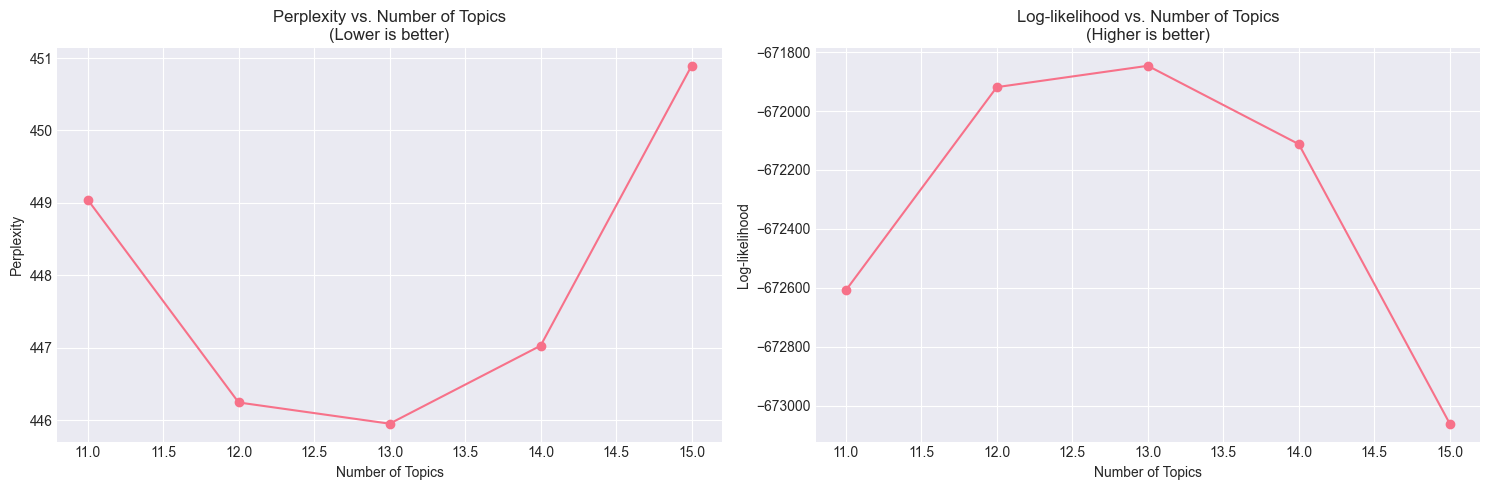

In [16]:
# Step 1: Parameter tuning
print("\n" + "="*70)
print("STEP 1: PARAMETER TUNING")
print("="*70)
results_df, best_n_topics = analyzer.tune_lda_parameters(
n_topics_range=[11, 12, 13, 14, 15],
max_iter=20,
n_samples=5000  # Use subset for faster tuning
)


## Model Training

In [17]:
# You can manually override the recommended number of topics
# best_n_topics = 15  # Uncomment to manually set

# Step 2: Train final model
print("\n" + "="*70)
print("STEP 2: TRAINING FINAL MODEL")
print("="*70)
analyzer.train_lda_model(n_topics=best_n_topics, max_iter=50)



STEP 2: TRAINING FINAL MODEL

TRAINING FINAL LDA MODEL WITH 13 TOPICS
Creating document-term matrix...
Vocabulary size: 2000
Document-term matrix shape: (1653, 2000)

Training LDA model with 13 topics...
iteration: 1 of max_iter: 50
iteration: 2 of max_iter: 50
iteration: 3 of max_iter: 50
iteration: 4 of max_iter: 50
iteration: 5 of max_iter: 50
iteration: 6 of max_iter: 50
iteration: 7 of max_iter: 50
iteration: 8 of max_iter: 50
iteration: 9 of max_iter: 50
iteration: 10 of max_iter: 50
iteration: 11 of max_iter: 50
iteration: 12 of max_iter: 50
iteration: 13 of max_iter: 50
iteration: 14 of max_iter: 50
iteration: 15 of max_iter: 50
iteration: 16 of max_iter: 50
iteration: 17 of max_iter: 50
iteration: 18 of max_iter: 50
iteration: 19 of max_iter: 50
iteration: 20 of max_iter: 50
iteration: 21 of max_iter: 50
iteration: 22 of max_iter: 50
iteration: 23 of max_iter: 50
iteration: 24 of max_iter: 50
iteration: 25 of max_iter: 50
iteration: 26 of max_iter: 50
iteration: 27 of max_ite

## Display Topics

In [ ]:
# Step 3: Display topics
print("\n" + "="*70)
print("STEP 3: ANALYZING TOPICS")
print("="*70)
topics_df = analyzer.display_topics(n_words=15)



STEP 3: ANALYZING TOPICS

TOP WORDS PER TOPIC

Topic 0:
  Words: sensor, module, map, pin, maps, test, data, meshtastic, home, gpio, sensors, device, telemetry, zoom, pins
  Documents: 24

Topic 1:
  Words: antenna, heltec, antennas, v3, range, sma, better, just, base, node, inside, box, case, mount, window
  Documents: 91

Topic 2:
  Words: node, channel, nodes, messages, mqtt, message, mesh, default, meshdash, set, private, send, longfast, public, settings
  Documents: 147

Topic 3:
  Words: nodes, meshtastic, node, network, mesh, like, use, area, devices, messages, using, message, ve, range, device
  Documents: 311

Topic 4:
  Words: amp, node, format, preview, width, redd, webp, auto, sightings, ve, png, thread, jpg, https, pjpg
  Documents: 63

Topic 5:
  Words: just, ve, meshtastic, got, work, new, really, like, don, use, know, need, help, deck, people
  Documents: 181

Topic 6:
  Words: battery, solar, power, panel, usb, node, batteries, rak, charging, charge, board, 18650, use

In [ ]:
# Spot-check the dataframe after training to confirm the expected columns
# (e.g. dominant_topic) are present.

print(analyzer.df.head(n=5))

## Create Visualizations


STEP 4: CREATING VISUALIZATIONS

VISUALIZING TOPIC SIMILARITY
Saved topic similarity visualization to 'topic_similarity.png'

VISUALIZING AUTHOR-TOPIC RELATIONSHIPS
Analyzing 25 authors with 5+ posts...
Saved author-topic visualization to 'author_topic_similarity.png'
Saved author-topic matrix to 'author_topic_matrix.csv'

TEMPORAL ANALYSIS
Saved temporal analysis to 'temporal_analysis.png'
Saved temporal data to 'temporal_analysis.csv'


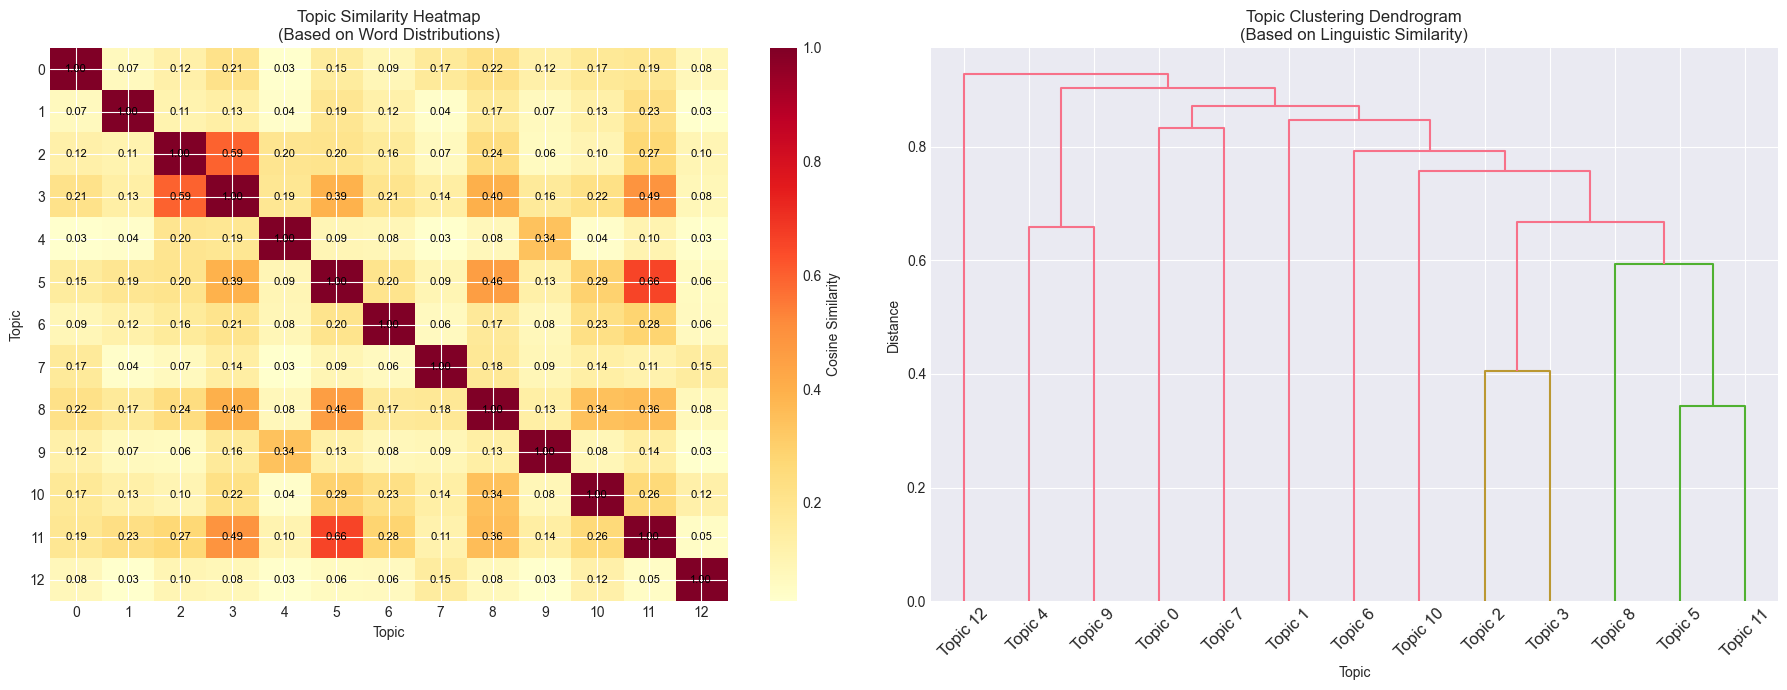

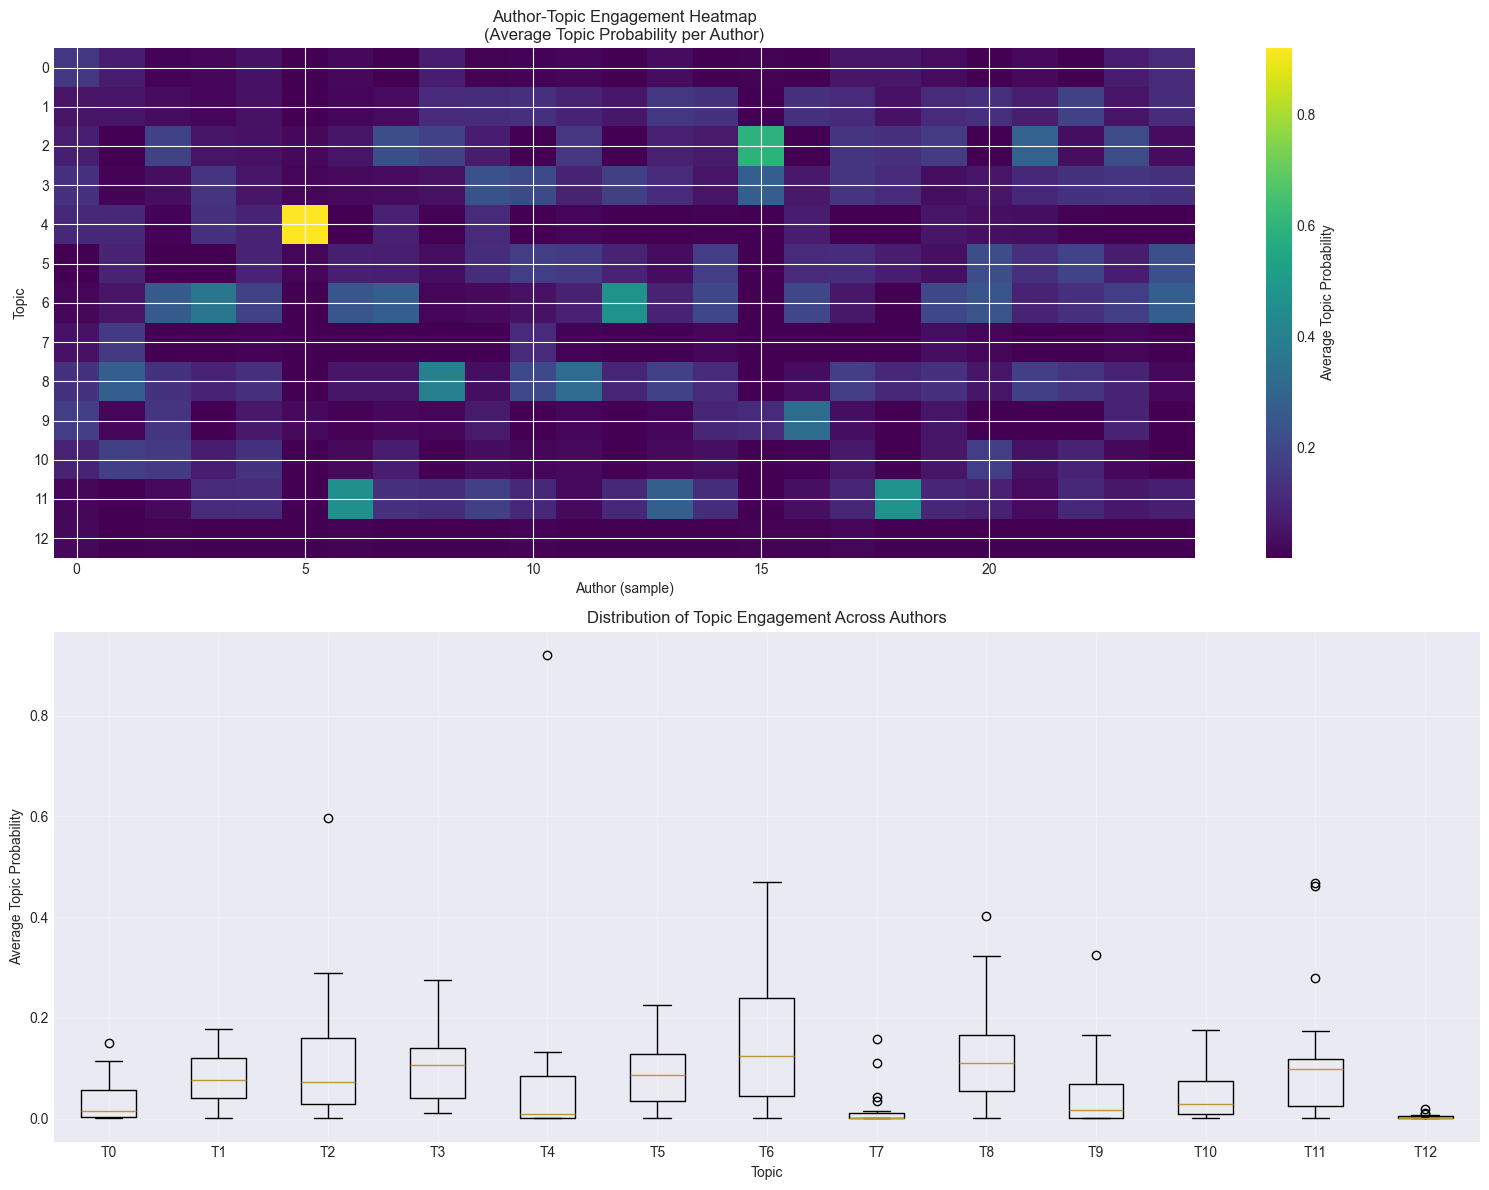

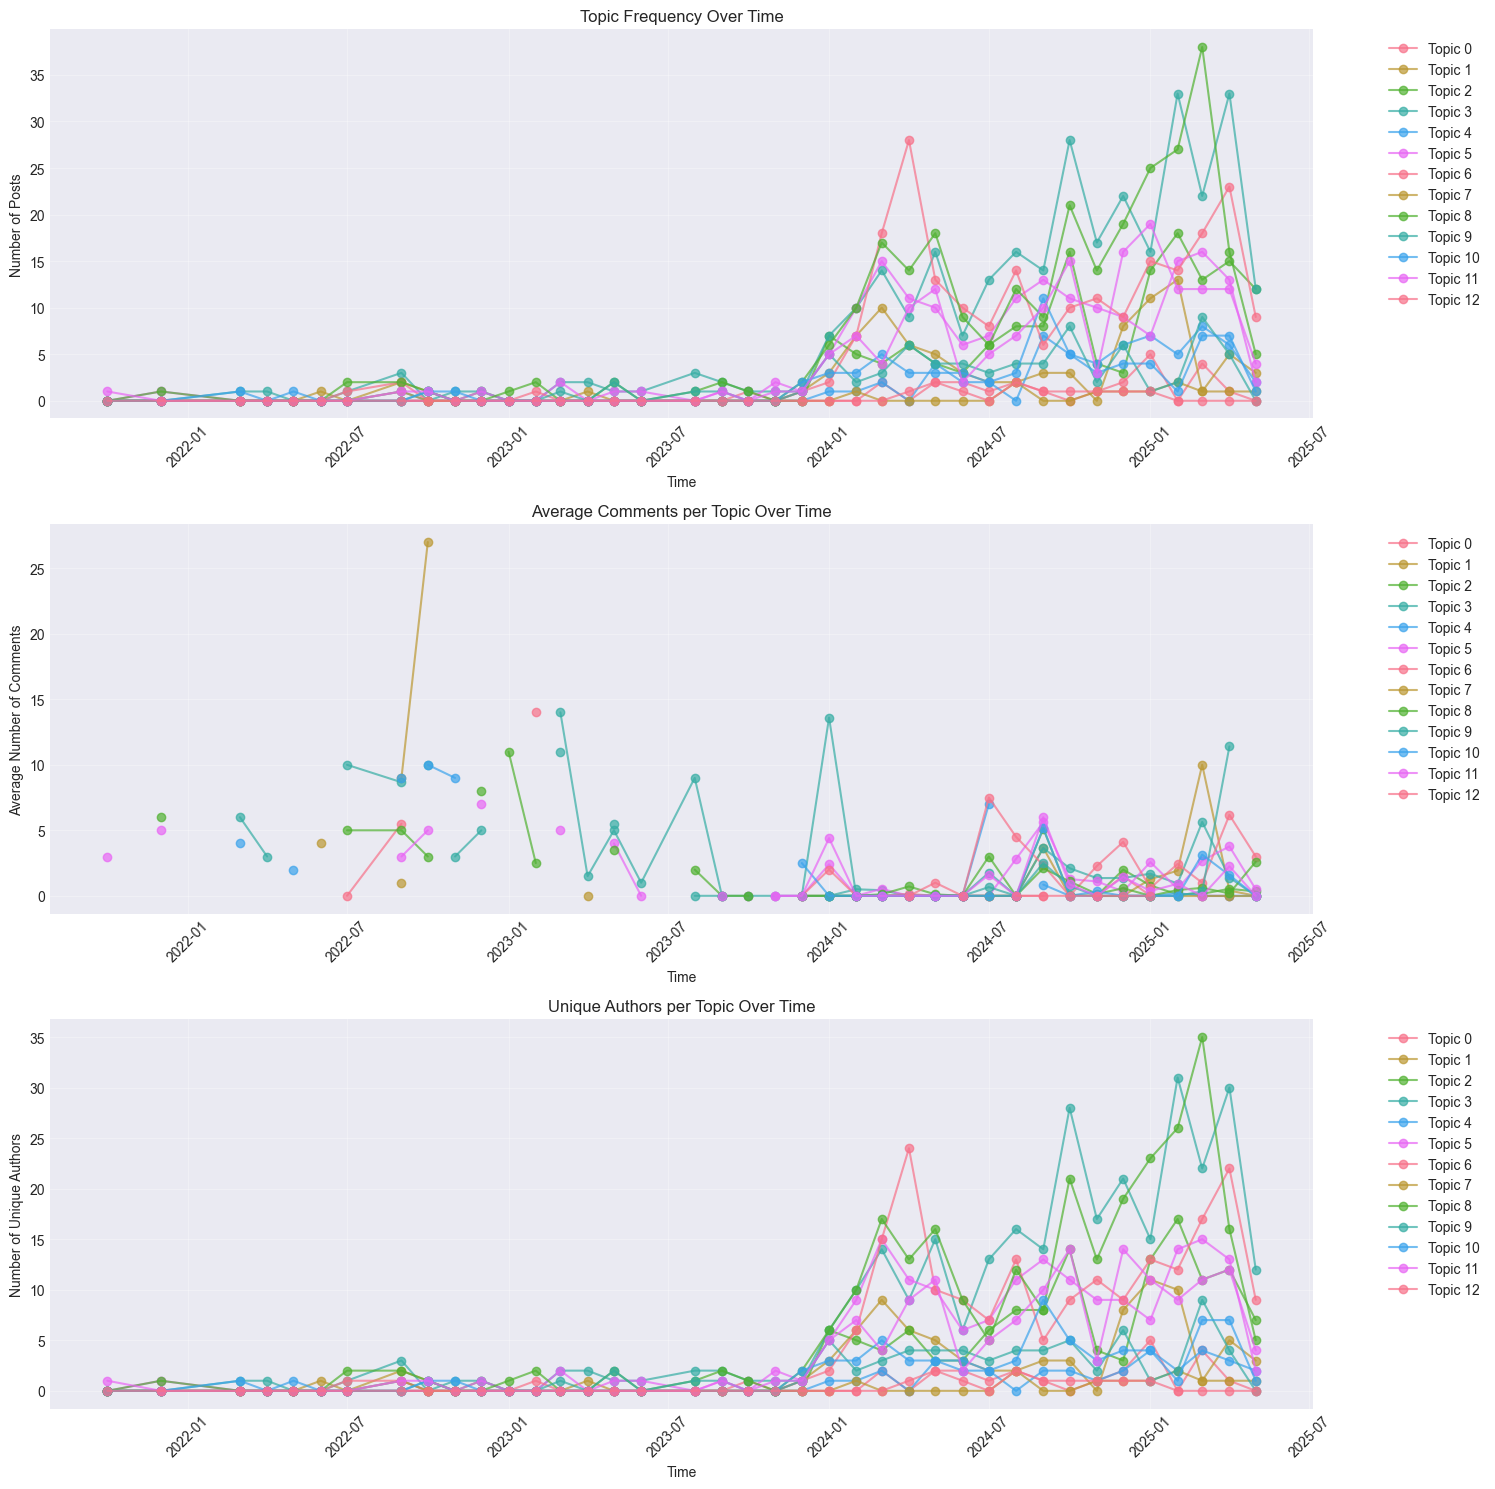

In [ ]:
# Step 4: Create visualizations
print("\n" + "="*70)
print("STEP 4: CREATING VISUALIZATIONS")
print("="*70)

analyzer.visualize_topic_similarity()
analyzer.visualize_author_topic_similarity()
analyzer.temporal_analysis()


## Sample Data by Topic

In [18]:
# Step 5: Purposive sampling
print("\n" + "="*70)
print("STEP 5: PURPOSIVE SAMPLING")
print("="*70)
sample1, sample2, sample3, sample4 = analyzer.sample_posts(n_per_topic=50)




STEP 5: PURPOSIVE SAMPLING

PURPOSIVE SAMPLING

Strategy 1: Even sampling prioritizing high engagement (num_comments)...
  Topic 0: sampled 24 posts (avg comments: 0.1)
  Topic 1: sampled 50 posts (avg comments: 2.2)
  Topic 2: sampled 50 posts (avg comments: 2.0)
  Topic 3: sampled 50 posts (avg comments: 10.8)
  Topic 4: sampled 50 posts (avg comments: 0.6)
  Topic 5: sampled 50 posts (avg comments: 5.9)
  Topic 6: sampled 50 posts (avg comments: 9.2)
  Topic 7: sampled 12 posts (avg comments: 0.1)
  Topic 8: sampled 50 posts (avg comments: 3.5)
  Topic 9: sampled 50 posts (avg comments: 3.6)
  Topic 10: sampled 50 posts (avg comments: 2.4)
  Topic 11: sampled 50 posts (avg comments: 3.6)
  Topic 12: sampled 11 posts (avg comments: 0.2)

Strategy 2: Random sampling across topics...
  Topic 0: sampled 24 posts
  Topic 1: sampled 50 posts
  Topic 2: sampled 50 posts
  Topic 3: sampled 50 posts
  Topic 4: sampled 50 posts
  Topic 5: sampled 50 posts
  Topic 6: sampled 50 posts
  Topic 

## Write Labeled Posts to CSV

In [ ]:
# Write every post, with its assigned topic and probability, out to a single labeled CSV.

analyzer.save_labeled_csv(str(MESHTASTIC_LDA_DIR / "all_posts_labeled.csv"))


In [ ]:
# Step 6: Generate report
analyzer.generate_full_report()

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)
print("\nGenerated files:")
print("  - parameter_tuning_results.png")
print("  - lda_model.pkl")
print("  - topics_summary.csv")
print("  - topic_similarity.png")
print("  - author_topic_similarity.png")
print("  - author_topic_matrix.csv")
print("  - temporal_analysis.png")
print("  - temporal_analysis.csv")
print("  - sample_high_engagement.csv")
print("  - sample_random_by_topic.csv")
print("  - sample_topical_relevance.csv")
print("  - sample_temporal_random.csv")
print("  - analysis_report.txt")
print("\nAll visualizations and samples have been saved!")



GENERATING COMPREHENSIVE REPORT

Report saved to 'analysis_report.txt'

REDDIT POSTS LDA TOPIC MODELING - COMPREHENSIVE REPORT

DATASET STATISTICS
----------------------------------------------------------------------
Total posts: 1,653
Date range: 2021-10-20 16:18:43 to 2025-05-20 02:28:01
Unique authors: 1,146
Total comments: 2,204
Average comments per post: 1.33
Std. dev. comments per post: 5.11

MODEL STATISTICS
----------------------------------------------------------------------
Number of topics: 13
Vocabulary size: 2,000
Perplexity: 787.77
Log-likelihood: -863508.97

TOPIC DISTRIBUTION
----------------------------------------------------------------------
Topic 0: 24 posts (1.5%) - Avg confidence: 0.453
Topic 1: 91 posts (5.5%) - Avg confidence: 0.462
Topic 2: 147 posts (8.9%) - Avg confidence: 0.556
Topic 3: 311 posts (18.8%) - Avg confidence: 0.544
Topic 4: 63 posts (3.8%) - Avg confidence: 0.736
Topic 5: 181 posts (10.9%) - Avg confidence: 0.465
Topic 6: 220 posts (13.3%) -

In [ ]:
# (Intended as a quick peek at the dataframe -- note this is missing the trailing
# parentheses, so it prints the bound method object rather than the actual rows.)

analyzer.df.head

## Comments

In [ ]:
# Load the per-comment CSV written out by a previous run of this notebook (see
# 'Write DFs to Data Structure' at the end) rather than re-parsing the raw JSON dump.

meshtastic_rca = RedditCommentAnalyzer(str(MESHTASTIC_COMMENTS_CSV), csv_file=True)


In [ ]:
# Keep only comments whose parent post survived preprocessing, by inner-joining on link_id.

meshtastic_rca.cross_ref_to_posts(analyzer.df)

In [ ]:
# Confirm analyzer.df still holds the full set of labeled posts.

print(analyzer.df)

In [ ]:
# Preview the joined comment dataframe.

print(meshtastic_rca.df.head(n=5))

In [ ]:
# Chart new vs. returning commenters over time.

create_new_vs_returning_users_chart(meshtastic_rca.df, time_unit='M', figsize=(15, 8),
                                        user_column='comment_author',
                                        date_column='comment_created_datetime',
                                        output_filepath=str(FIG_DIR / "meshtastic_new_commenters.png"))


## Visualizations

In [ ]:
# Map each LDA topic to a human-readable category, then plot post volume per category over time.

meshtastic_topic_groups = {'Deployment Logistics' : [8, 6, 2, 1, 10, 0],
                           'Troubleshooting':[7, 12],
                           'Community engagement': [3],
                           'Onboarding experience': [5],
                           'Motivations': [11],
                           'Resource sharing': [9],
                           'Weekly node sighting': [4]}
create_stacked_area_chart_with_merging(analyzer.df, meshtastic_topic_groups, time_unit='M',
                                          figsize=(15, 8),
                                          output_filepath=str(FIG_DIR / "meshtastic_stacked_posts_per_topic.png"))


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FONTSIZE = 18

# Filter to topics 3 and 11
df_filtered = analyzer.df[analyzer.df["dominant_topic"].isin([3, 11])].copy()
df_filtered["year_month"] = pd.to_datetime(df_filtered["created_datetime"]).dt.to_period("M")

# Count posts per topic per month
monthly = (
    df_filtered.groupby(["year_month", "dominant_topic"])
    .size()
    .reset_index(name="post_count")
)

# Zero-fill months where a topic had no posts
idx = pd.MultiIndex.from_product(
    [sorted(monthly["year_month"].unique()), [3, 11]],
    names=["year_month", "dominant_topic"]
)
monthly = (
    monthly.set_index(["year_month", "dominant_topic"])
    .reindex(idx, fill_value=0)
    .reset_index()
    .sort_values(["dominant_topic", "year_month"])
)

# Relative month-over-month change per topic
monthly["rel_change"] = (
    monthly.groupby("dominant_topic")["post_count"].pct_change() * 100
)
monthly["rel_change"] = monthly["rel_change"].replace([float("inf"), float("-inf")], float("nan"))
monthly["year_month"] = monthly["year_month"].dt.to_timestamp()
monthly["dominant_topic"] = "Topic " + monthly["dominant_topic"].astype(str)

print(monthly.to_string(index=False))

# Plot
sns.set_style("darkgrid", {"axes.facecolor": "#d3d3d3"})
topics = sorted(monthly["dominant_topic"].unique())
palette = dict(zip(topics, sns.color_palette("viridis", len(topics))))

fig, ax = plt.subplots(figsize=(13, 6))
sns.lineplot(data=monthly, x="year_month", y="rel_change",
             hue="dominant_topic", hue_order=topics, palette=palette, ax=ax)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_xlabel("Month", fontsize=FONTSIZE)
ax.set_ylabel("Month-over-Month Change (%)", fontsize=FONTSIZE)
ax.set_title("Relative Change in Posts — Topics 3 & 11 (Meshtastic)", fontsize=FONTSIZE)
ax.tick_params(labelsize=FONTSIZE)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles, labels, title="Dominant Topic", frameon=True,
          framealpha=1.0, facecolor="white", edgecolor="gray",
          title_fontsize=FONTSIZE, fontsize=FONTSIZE, loc="upper left")
plt.tight_layout()
plt.savefig(str(REV_GROUP_FIG_DIR / "meshtastic_rel_change_topics3_11.png"),
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Show the month-over-month change in Topic 3 ("Community engagement") post volume.

print(monthly[monthly["dominant_topic"] == "Topic 3"][["year_month", "post_count", "rel_change"]].to_string(index=False))

In [ ]:
# Show the month-over-month change in Topic 11 ("Motivations") post volume.

print(monthly[monthly["dominant_topic"] == "Topic 11"][["year_month", "post_count", "rel_change"]].to_string(index=False))

In [ ]:
# Export Topic 11 posts from 2024-01-01 to 2024-04-30 for closer manual review.

start = "2024-01-01"
end = "2024-04-30"

mask = (
    pd.to_datetime(analyzer.df["created_datetime"]).between(start, end) &
    analyzer.df["dominant_topic"].isin([11])
)
analyzer.df[mask].to_csv(
    str(MESHTASTIC_LDA_DIR / "meshtastic_posts_topics11_2024-01-01_to_2024-04-30.csv"),
    index=False,
)


In [ ]:
# Export Topic 11 posts from 2024-12-01 to 2024-12-31 for closer manual review.

start = "2024-12-01"
end = "2024-12-31"

mask = (
    pd.to_datetime(analyzer.df["created_datetime"]).between(start, end) &
    analyzer.df["dominant_topic"].isin([11])
)
analyzer.df[mask].to_csv(
    str(MESHTASTIC_LDA_DIR / "meshtastic_posts_topics11_2024-12-01_to_2024-12-31.csv"),
    index=False,
)


In [ ]:
# Export Topic 3 posts from 2024-01-01 to 2024-03-31 for closer manual review.

start = "2024-01-01"
end = "2024-03-31"

mask = (
    pd.to_datetime(analyzer.df["created_datetime"]).between(start, end) &
    analyzer.df["dominant_topic"].isin([3])
)
analyzer.df[mask].to_csv(
    str(MESHTASTIC_LDA_DIR / "meshtastic_posts_topics3_2024-01-01_to_2024-03-31.csv"),
    index=False,
)


In [ ]:
# Plot the ECDF of post counts per author to see how activity is distributed across users.

compute_user_activity_ecdf(analyzer.df, time_unit='M', user_column='author_hash',
                               date_column='created_datetime', min_posts=1)

In [ ]:
# Chart new vs. returning original-posters (not commenters) over time.

create_new_vs_returning_users_chart(analyzer.df, time_unit='M', figsize=(15, 8),
                                        user_column='author_hash',
                                        date_column='created_datetime',
                                        output_filepath=str(FIG_DIR / "meshtastic_new_ops.png"))


In [ ]:
# Plot the ECDF of comment counts per commenter.

compute_user_activity_ecdf(meshtastic_rca.df, time_unit='M', user_column='comment_author',
                               date_column='comment_created_datetime', min_posts=1)

## Retention

### Monthly

In [ ]:
# Monthly Retention

retention_monthly, stats_monthly = compute_retention_rates(
    meshtastic_rca.df,
    time_unit='M', user_column="comment_author", date_column="comment_created_datetime"
)

# Plot
fig1, ax1 = plot_retention_over_time(retention_monthly, stats_monthly)
plt.savefig(str(FIG_DIR / "meshtastic_retention_monthly_comments.png"), dpi=300, bbox_inches='tight')
plt.close()


In [ ]:
# Quarterly Retention

retention_quarterly, stats_quarterly = compute_retention_rates(
    meshtastic_rca.df,
    time_unit='Q', user_column="comment_author", date_column="comment_created_datetime"
)

# Plot
fig1, ax1 = plot_retention_over_time(retention_quarterly, stats_quarterly)
plt.savefig(str(FIG_DIR / "meshtastic_retention_quarterly_comments.png"), dpi=300, bbox_inches='tight')
plt.close()


### Across all

In [ ]:
# Compare retention rates computed at monthly, quarterly, and six-month granularities on one chart.

fig4, all_results = compare_retention_across_periods(meshtastic_rca.df)
plt.savefig(str(FIG_DIR / "meshtastic_retention_comparison_comments.png"), dpi=300, bbox_inches='tight')
plt.close()


In [ ]:
# Build a cohort heatmap: group users by the 6-month period they first commented in, then
# track what fraction of each cohort is still active in each subsequent period.

cohort_df, fig5 = cohort_retention_analysis(
    meshtastic_rca.df,
    time_unit='6M',
    n_periods=12  # Track for 12 months
)

plt.savefig(str(FIG_DIR / "meshtastic_cohort_retention_heatmap_monthly.png"), dpi=300, bbox_inches='tight')


In [ ]:
# Confirm the date range covered by the labeled Meshtastic posts.

print(analyzer.df["created_datetime"].min())
print(analyzer.df["created_datetime"].max())

# Execution for Helium


## Read in the Data

In [ ]:
print("="*70)
print("REDDIT LDA TOPIC MODELING ANALYSIS")
print("="*70)
print("\nThis script will guide you through:")
print("1. Loading and preprocessing data")
print("2. Tuning LDA parameters")
print("3. Training the final model")
print("4. Creating visualizations")
print("5. Performing purposive sampling")
print()

# Initialize analyzer
h_analyzer = RedditLDAAnalyzer(HELIUM_POSTS_CSV, str(HELIUM_LDA_DIR))

# Preprocess data
h_analyzer.preprocess_data()


## Parameter Tuning


STEP 1: PARAMETER TUNING

PARAMETER TUNING
Sampling 5000 documents for parameter tuning...
Creating document-term matrix...
Vocabulary size: 1000

Testing 7 topics...
  Perplexity: 461.73
  Log-likelihood: -1866061.04

Testing 8 topics...
  Perplexity: 448.51
  Log-likelihood: -1857223.65

Testing 9 topics...
  Perplexity: 451.28
  Log-likelihood: -1859097.51

Testing 10 topics...
  Perplexity: 438.91
  Log-likelihood: -1850641.12

Testing 11 topics...
  Perplexity: 433.72
  Log-likelihood: -1847024.08

Testing 12 topics...
  Perplexity: 430.58
  Log-likelihood: -1844809.93

Testing 13 topics...
  Perplexity: 435.94
  Log-likelihood: -1848579.21

Testing 14 topics...
  Perplexity: 431.72
  Log-likelihood: -1845620.03

Saved parameter tuning plot to 'parameter_tuning_results.png'

----------------------------------------------------------------------
RECOMMENDATION: Based on perplexity, 12 topics seems optimal
----------------------------------------------------------------------


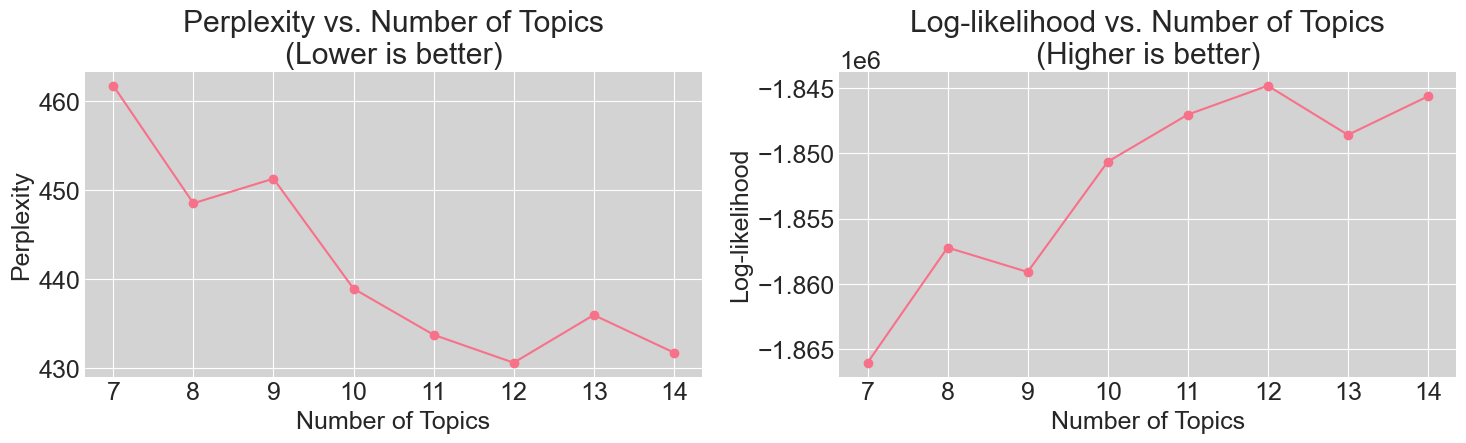

In [38]:
# Step 1: Parameter tuning
print("\n" + "="*70)
print("STEP 1: PARAMETER TUNING")
print("="*70)
results_df, best_n_topics = h_analyzer.tune_lda_parameters(
n_topics_range=[7, 8, 9, 10, 11, 12, 13, 14],
max_iter=20,
n_samples=5000  # Use subset for faster tuning
)


## Model Training

In [39]:
# You can manually override the recommended number of topics
# best_n_topics = 15  # Uncomment to manually set

# Step 2: Train final model
print("\n" + "="*70)
print("STEP 2: TRAINING FINAL MODEL")
print("="*70)
h_analyzer.train_lda_model(n_topics=best_n_topics, max_iter=50)



STEP 2: TRAINING FINAL MODEL

TRAINING FINAL LDA MODEL WITH 12 TOPICS
Creating document-term matrix...
Vocabulary size: 2000
Document-term matrix shape: (5267, 2000)

Training LDA model with 12 topics...
iteration: 1 of max_iter: 50
iteration: 2 of max_iter: 50
iteration: 3 of max_iter: 50
iteration: 4 of max_iter: 50
iteration: 5 of max_iter: 50
iteration: 6 of max_iter: 50
iteration: 7 of max_iter: 50
iteration: 8 of max_iter: 50
iteration: 9 of max_iter: 50
iteration: 10 of max_iter: 50
iteration: 11 of max_iter: 50
iteration: 12 of max_iter: 50
iteration: 13 of max_iter: 50
iteration: 14 of max_iter: 50
iteration: 15 of max_iter: 50
iteration: 16 of max_iter: 50
iteration: 17 of max_iter: 50
iteration: 18 of max_iter: 50
iteration: 19 of max_iter: 50
iteration: 20 of max_iter: 50
iteration: 21 of max_iter: 50
iteration: 22 of max_iter: 50
iteration: 23 of max_iter: 50
iteration: 24 of max_iter: 50
iteration: 25 of max_iter: 50
iteration: 26 of max_iter: 50
iteration: 27 of max_ite

## Display Topics

In [40]:
# Step 3: Display topics
print("\n" + "="*70)
print("STEP 3: ANALYZING TOPICS")
print("="*70)
topics_df = h_analyzer.display_topics(n_words=15)


STEP 3: ANALYZING TOPICS

TOP WORDS PER TOPIC

Topic 0:
  Words: order, miner, nebra, miners, shipping, bobcat, just, ordered, batch, refund, time, like, email, units, weeks
  Documents: 425

Topic 1:
  Words: gt, info, lt, gateway, 12, 2022, lora, 2021, 18, error, helium, 00, 22, 13, 2023
  Documents: 20

Topic 2:
  Words: app, wallet, helium, miner, hotspot, location, new, just, hnt, address, phone, account, tried, help, sol
  Documents: 567

Topic 3:
  Words: https, com, helium, www, hotspot, hotspots, community, network, discord, io, explorer, docs, team, reddit, data
  Documents: 201

Topic 4:
  Words: mobile, hip, helium, network, vote, rewards, iot, https, com, heliumvote, voting, data, coverage, governance, cbrs
  Documents: 164

Topic 5:
  Words: network, helium, hotspot, hotspots, people, like, use, data, coverage, devices, just, way, know, need, internet
  Documents: 747

Topic 6:
  Words: amp, x200b, https, png, auto, format, width, redd, webp, preview, jpg, pjpg, serial, 

## Create Visualizations


STEP 4: CREATING VISUALIZATIONS

VISUALIZING TOPIC SIMILARITY
Saved topic similarity visualization to 'topic_similarity.png'

VISUALIZING AUTHOR-TOPIC RELATIONSHIPS
Analyzing 68 authors with 5+ posts...
Saved author-topic visualization to 'author_topic_similarity.png'
Saved author-topic matrix to 'author_topic_matrix.csv'

TEMPORAL ANALYSIS
Saved temporal analysis to 'temporal_analysis.png'
Saved temporal data to 'temporal_analysis.csv'


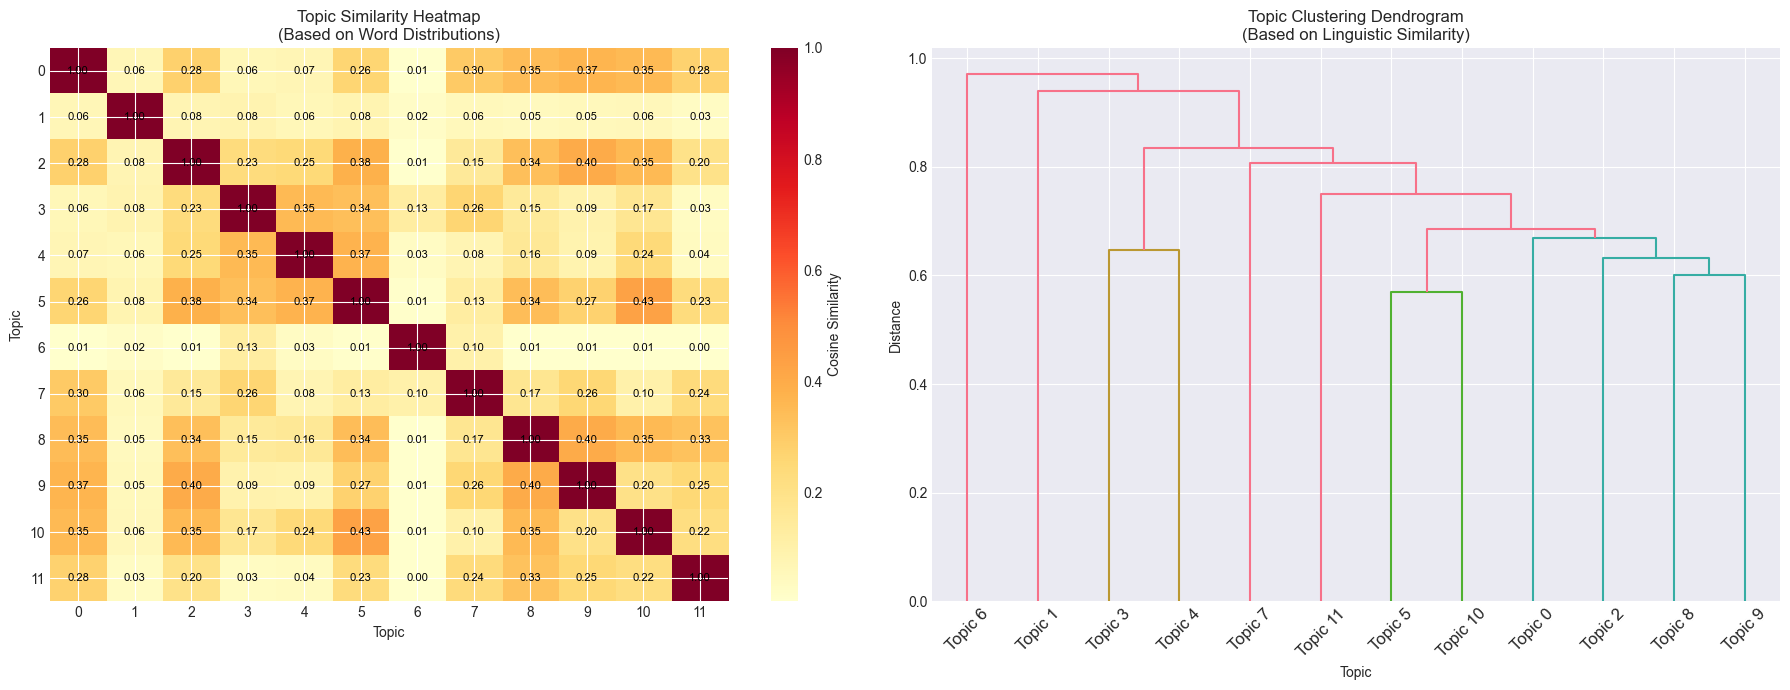

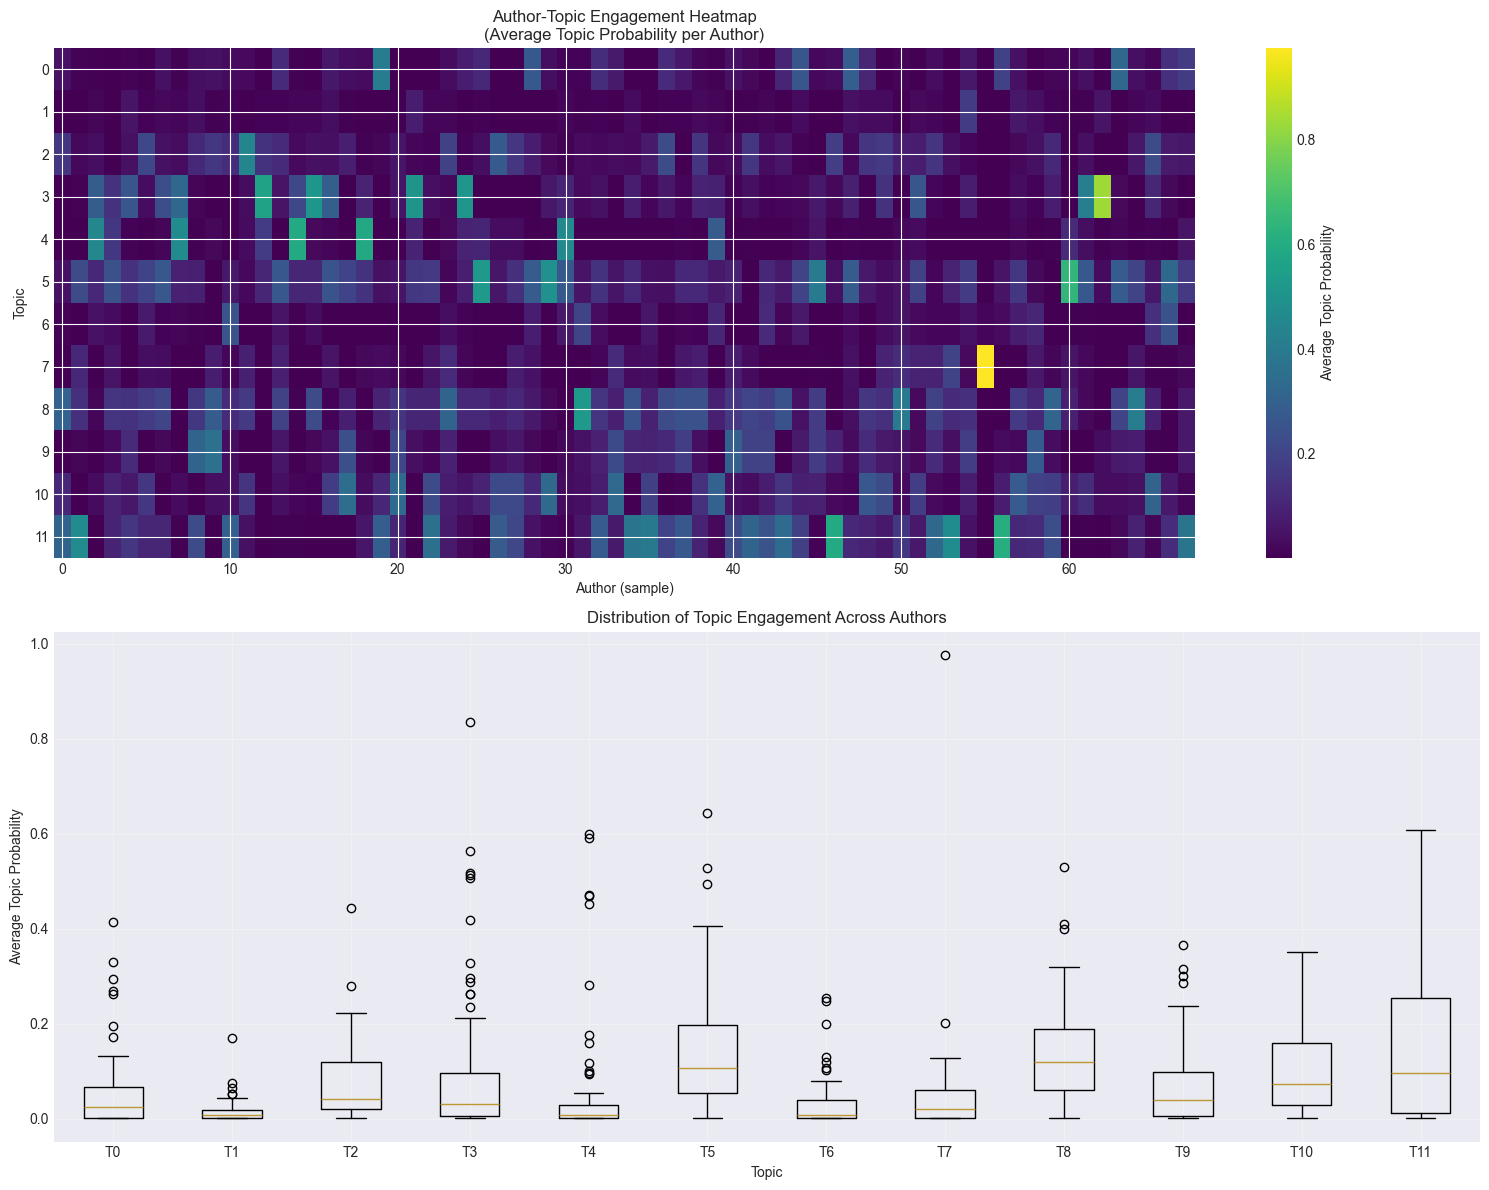

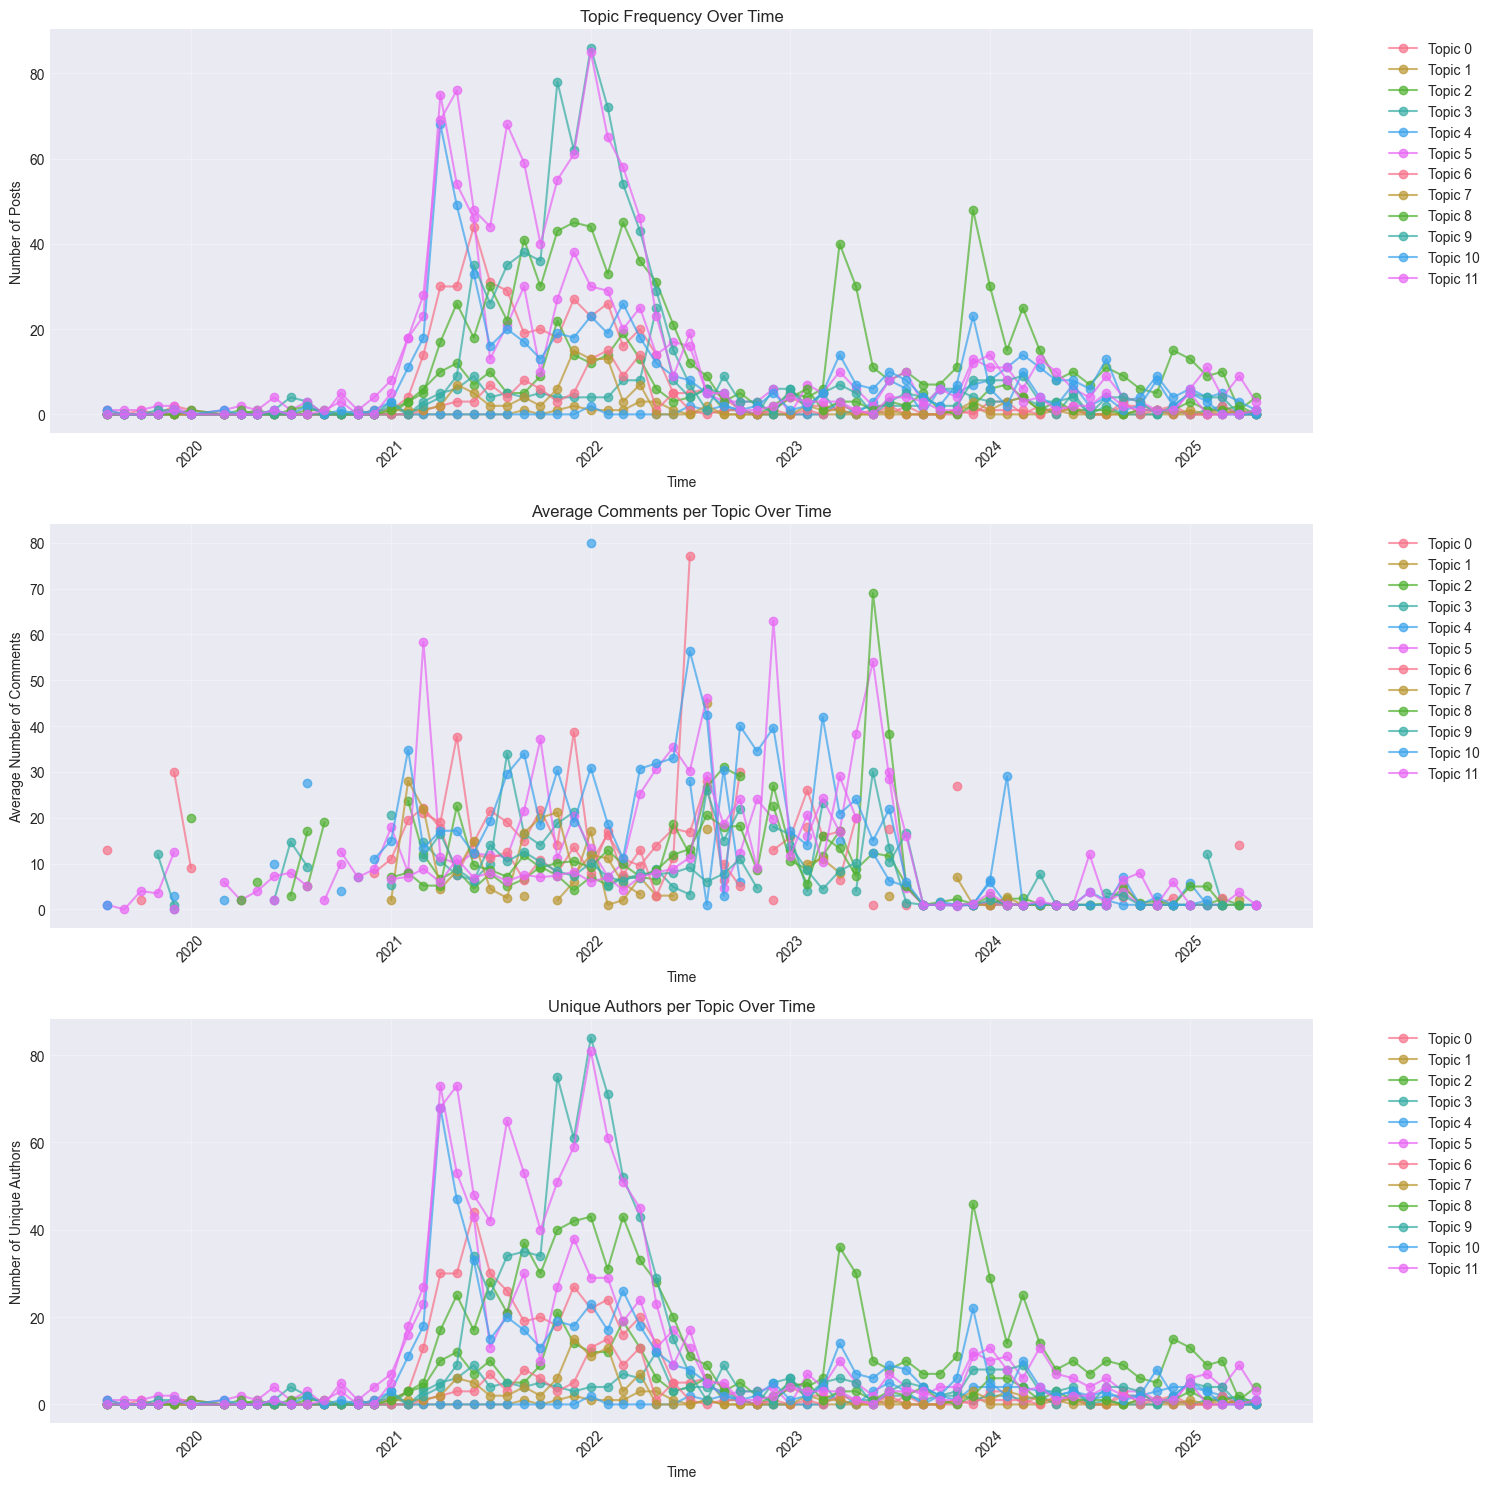

In [ ]:
# Step 4: Create visualizations
print("\n" + "="*70)
print("STEP 4: CREATING VISUALIZATIONS")
print("="*70)

h_analyzer.visualize_topic_similarity()
h_analyzer.visualize_author_topic_similarity()
h_analyzer.temporal_analysis()


## Sample Data by Topic

In [ ]:
# Step 5: Purposive sampling
print("\n" + "="*70)
print("STEP 5: PURPOSIVE SAMPLING")
print("="*70)
sample1, sample2, sample3, sample4 = h_analyzer.sample_posts(n_per_topic=50)



STEP 5: PURPOSIVE SAMPLING

PURPOSIVE SAMPLING

Strategy 1: Even sampling prioritizing high engagement (num_comments)...
  Topic 0: sampled 50 posts (avg comments: 71.2)
  Topic 1: sampled 20 posts (avg comments: 6.3)
  Topic 2: sampled 50 posts (avg comments: 31.7)
  Topic 3: sampled 50 posts (avg comments: 30.8)
  Topic 4: sampled 50 posts (avg comments: 11.7)
  Topic 5: sampled 50 posts (avg comments: 104.0)
  Topic 6: sampled 50 posts (avg comments: 22.7)
  Topic 7: sampled 50 posts (avg comments: 17.4)
  Topic 8: sampled 50 posts (avg comments: 51.1)
  Topic 9: sampled 50 posts (avg comments: 38.5)
  Topic 10: sampled 50 posts (avg comments: 109.5)
  Topic 11: sampled 50 posts (avg comments: 42.1)

Strategy 2: Random sampling across topics...
  Topic 0: sampled 50 posts
  Topic 1: sampled 20 posts
  Topic 2: sampled 50 posts
  Topic 3: sampled 50 posts
  Topic 4: sampled 50 posts
  Topic 5: sampled 50 posts
  Topic 6: sampled 50 posts
  Topic 7: sampled 50 posts
  Topic 8: sample

## Write Labeled Posts to CSV

In [ ]:
# Write every Helium post, with its assigned topic and probability, out to a single labeled CSV.

h_analyzer.save_labeled_csv(str(HELIUM_LDA_DIR / "all_posts_labeled.csv"))


### Data Visualization

In [ ]:
# Chart new vs. returning original-posters over time for Helium.

create_new_vs_returning_users_chart(h_analyzer.df, time_unit='M', figsize=(15, 8),
                                        user_column='author_hash',
                                        date_column='created_datetime',
                                        output_filepath=str(FIG_DIR / "helium_new_ops.png"))


In [ ]:
# Plot the ECDF of post counts per author for Helium.

compute_user_activity_ecdf(h_analyzer.df, time_unit='M', user_column='author_hash',
                               date_column='created_datetime', min_posts=1)

In [ ]:
# Map each LDA topic to a human-readable category, then plot post volume per category over time.

helium_topic_groups = {'Deployment Logistics' : [11, 7],
                           'Troubleshooting':[9, 6, 1],
                           'Community engagement': [3],
                           'Network governance': [4],
                           'Project vision': [5],
                           'Witnessing & reward': [8],
                           'Token value & economy': [10],
                           'Issues with Helium app & wallet': [2],
                           'Issues with miner ordering': [0]}
create_stacked_area_chart_with_merging(h_analyzer.df, helium_topic_groups, time_unit='M',
                                          figsize=(15, 8),
                                          output_filepath=str(FIG_DIR / "helium_stacked_area_posts_by_topic.png"))


## Extracting posts from periods of change

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FONTSIZE = 18

# Filter to topics 2, 3, 4, 5, 8, 10
df_filtered = h_analyzer.df[h_analyzer.df["dominant_topic"].isin([2,3,4,5,8,10])].copy()
df_filtered["year_month"] = pd.to_datetime(df_filtered["created_datetime"]).dt.to_period("M")

# Count posts per topic per month
monthly = (
    df_filtered.groupby(["year_month", "dominant_topic"])
    .size()
    .reset_index(name="post_count")
)

# Zero-fill months where a topic had no posts
idx = pd.MultiIndex.from_product(
    [sorted(monthly["year_month"].unique()), [2, 3, 4, 5, 8, 10]],
    names=["year_month", "dominant_topic"]
)
monthly = (
    monthly.set_index(["year_month", "dominant_topic"])
    .reindex(idx, fill_value=0)
    .reset_index()
    .sort_values(["dominant_topic", "year_month"])
)

# Relative month-over-month change per topic
monthly["rel_change"] = (
    monthly.groupby("dominant_topic")["post_count"].pct_change() * 100
)
monthly["rel_change"] = monthly["rel_change"].replace([float("inf"), float("-inf")], float("nan"))
monthly["year_month"] = monthly["year_month"].dt.to_timestamp()
monthly["dominant_topic"] = "Topic " + monthly["dominant_topic"].astype(str)

print(monthly.to_string(index=False))


year_month dominant_topic  post_count  rel_change
2019-08-01        Topic 2           0         NaN
2019-09-01        Topic 2           0         NaN
2019-10-01        Topic 2           0         NaN
2019-11-01        Topic 2           0         NaN
2019-12-01        Topic 2           0         NaN
2020-01-01        Topic 2           0         NaN
2020-03-01        Topic 2           0         NaN
2020-04-01        Topic 2           0         NaN
2020-05-01        Topic 2           1         NaN
2020-06-01        Topic 2           0 -100.000000
2020-07-01        Topic 2           0         NaN
2020-08-01        Topic 2           1         NaN
2020-09-01        Topic 2           1    0.000000
2020-10-01        Topic 2           0 -100.000000
2020-11-01        Topic 2           0         NaN
2020-12-01        Topic 2           0         NaN
2021-01-01        Topic 2           0         NaN
2021-02-01        Topic 2           3         NaN
2021-03-01        Topic 2           6  100.000000


In [ ]:
# Show the month-over-month change in Topic 8 ("Witnessing & reward") post volume.

print(monthly[monthly["dominant_topic"] == "Topic 8"][["year_month", "post_count", "rel_change"]].to_string(index=False))

## Comments

In [ ]:
# NOTE: previously called with a `post_df=` keyword argument that
# RedditCommentAnalyzer.__init__ does not accept (it only takes
# `base_directory` and `csv_file`) — that call would raise a TypeError.
# Fixed to match the constructor signature and load straight from the
# raw per-comment JSON directory, same as the `csv_file=False` branch
# used elsewhere in this notebook.
helium_rca = RedditCommentAnalyzer(str(HELIUM_COMMENTS_DIR), csv_file=False)


In [ ]:
# Chart new vs. returning commenters over time for Helium.

create_new_vs_returning_users_chart(helium_rca.df, time_unit='M', figsize=(15, 8),
                                        user_column='comment_author',
                                        date_column='comment_created_datetime',
                                        output_filepath=str(FIG_DIR / "helium_new_commenters.png"))


In [ ]:
# Plot the ECDF of comment counts per commenter for Helium.

compute_user_activity_ecdf(helium_rca.df, time_unit='M', user_column='comment_author',
                               date_column='comment_created_datetime', min_posts=1)

## Retention

In [ ]:
# Monthly Retention

retention_monthly, stats_monthly = compute_retention_rates(
    helium_rca.df,
    time_unit='M', user_column="comment_author", date_column="comment_created_datetime"
)

# Plot
fig1, ax1 = plot_retention_over_time(retention_monthly, stats_monthly)
plt.savefig(str(FIG_DIR / "helium_retention_monthly_comments.png"), dpi=300, bbox_inches='tight')
plt.close()


In [ ]:
# Confirm the date range covered by the labeled Helium posts.

print(h_analyzer.df["created_datetime"].min())
print(h_analyzer.df["created_datetime"].max())

# Retention Analysis

Integrated from `rolling_retention_code.py` (originally a standalone script). This adds a *rolling*, backward-looking retention measure that complements the period-to-period retention computed above: for users active in period T, what fraction were also active at some point in each of the previous N periods (e.g. the previous 1, 3, or 6 months)? A higher rolling retention rate than the period-to-period rate indicates users who skip a period but return later, rather than churning outright.

Applied here to the comment data for each dataset (`comment_author` / `comment_created_datetime`), consistent with the period-to-period retention analysis above.

## Functions

In [ ]:
import scipy.stats

"""
=============================================================================
MAIN FUNCTION: Rolling Retention Analysis
=============================================================================
"""

def compute_rolling_retention(df, base_unit='M', window_sizes=[1, 3, 6],
                              user_column='author_hash',
                              date_column='created_datetime',
                              start_date = None):
    """
    Compute rolling retention rates with backward-looking windows.

    For users who posted in period T, what proportion were also active
    in the previous N periods?

    Examples:
    - window_size=1, base_unit='M': If user posted in March, were they in February?
    - window_size=3, base_unit='M': If user posted in March, were they in Dec-Feb (previous quarter)?
    - window_size=6, base_unit='M': If user posted in March, were they in Sep-Feb (previous 6 months)?

    Parameters:
    -----------
    df : DataFrame
        DataFrame with user IDs and timestamps
    base_unit : str
        Base time unit: 'M' (monthly), 'W' (weekly)
    window_sizes : list
        List of window sizes in base_unit periods (e.g., [1, 3, 6] for 1, 3, 6 months)
    user_column : str
        Name of column containing user IDs
    date_column : str
        Name of column containing datetime

    Returns:
    --------
    results_dict : dict
        Dictionary with retention results for each window size
    """
    # Prepare data
    df_copy = df.copy()

    # Ensure datetime format
    if date_column not in df_copy.columns and 'created_utc' in df_copy.columns:
        df_copy[date_column] = pd.to_datetime(df_copy['created_utc'], unit='s')
    else:
        df_copy[date_column] = pd.to_datetime(df_copy[date_column])

    # If there is a start date
    if start_date != None:
        start_date = pd.to_datetime(start_date, unit = "s")
        df_copy = df_copy[df_copy[date_column] >= start_date]

    # Create time periods
    df_copy['period'] = df_copy[date_column].dt.to_period(base_unit)

    # Get unique users per period
    period_users = df_copy.groupby('period')[user_column].apply(set).to_dict()

    # Sort periods
    all_periods = sorted(period_users.keys())

    print("="*70)
    print("ROLLING RETENTION ANALYSIS")
    print("="*70)
    print(f"Base unit: {base_unit}")
    print(f"Total periods: {len(all_periods)}")
    print(f"Date range: {all_periods[0]} to {all_periods[-1]}")
    print(f"Window sizes: {window_sizes} {base_unit} periods")

    results_dict = {}

    # Compute retention for each window size
    for window_size in window_sizes:
        print(f"\nComputing {window_size}-{base_unit} rolling retention...")

        retention_data = []

        # Start from window_size periods in (need history)
        for i in range(window_size, len(all_periods)):
            current_period = all_periods[i]

            # Users in current period
            users_current = period_users[current_period]
            n_current = len(users_current)

            if n_current == 0:
                continue

            # Get all users from previous window_size periods
            prev_periods = all_periods[i-window_size:i]
            users_in_window = set()
            for prev_period in prev_periods:
                users_in_window.update(period_users[prev_period])

            # How many current users were also in the previous window?
            n_retained = len(users_current & users_in_window)

            # Retention rate
            retention_rate = n_retained / n_current if n_current > 0 else 0

            retention_data.append({
                'period': current_period.to_timestamp(),
                'period_label': str(current_period),
                'window_size': window_size,
                'users_in_period': n_current,
                'users_retained': n_retained,
                'users_new': n_current - n_retained,
                'retention_rate': retention_rate,
                'retention_percentage': retention_rate * 100,
                'new_user_percentage': (1 - retention_rate) * 100
            })

        retention_df = pd.DataFrame(retention_data)

        # Compute statistics
        stats = {
            'window_size': window_size,
            'base_unit': base_unit,
            'mean_retention_rate': retention_df['retention_rate'].mean(),
            'median_retention_rate': retention_df['retention_rate'].median(),
            'std_retention_rate': retention_df['retention_rate'].std(),
            'min_retention_rate': retention_df['retention_rate'].min(),
            'max_retention_rate': retention_df['retention_rate'].max(),
            'total_periods_analyzed': len(retention_df)
        }

        results_dict[window_size] = {
            'retention_df': retention_df,
            'stats': stats
        }

        # Print results
        mean_pct = stats['mean_retention_rate'] * 100
        print(f"  Mean retention: {mean_pct:.2f}%")
        print(f"  (On average, {mean_pct:.2f}% of users who post in period T")
        print(f"   were also active in the previous {window_size} {base_unit} period(s))")

    return results_dict


"""
=============================================================================
VISUALIZATION: Plot Rolling Retention Rates
=============================================================================
"""

def plot_rolling_retention(results_dict, figsize=(15, 8)):
    """
    Plot rolling retention rates for all window sizes on one plot.

    Parameters:
    -----------
    results_dict : dict
        Output from compute_rolling_retention
    figsize : tuple
        Figure size

    Returns:
    --------
    fig, ax : matplotlib figure and axis
    """
    fig, ax = plt.subplots(figsize=figsize)

    colors = ['#653073', '#49a3a0', '#b9de57']
    window_labels = {
        1: '1 period back',
        3: '3 periods back (quarter)',
        6: '6 periods back (half-year)',
        12: '12 periods back (year)'
    }

    # Plot each window size
    for idx, (window_size, data) in enumerate(sorted(results_dict.items())):
        retention_df = data['retention_df']
        stats = data['stats']

        base_unit = stats['base_unit']
        label_text = window_labels.get(window_size, f'{window_size} periods back')
        if base_unit == 'M':
            if window_size == 1:
                label_text = 'Previous 1 month'
            elif window_size == 3:
                label_text = 'Previous 3 months (quarter)'
            elif window_size == 6:
                label_text = 'Previous 6 months'
            elif window_size == 12:
                label_text = 'Previous 12 months (year)'
            else:
                label_text = f'Previous {window_size} months'

        color = colors[idx % len(colors)]
        mean_pct = stats['mean_retention_rate'] * 100

        ax.plot(retention_df['period'],
                retention_df['retention_percentage'],
                marker='o',
                linewidth=2.5,
                markersize=6,
                color=color,
                label=f"{label_text} (mean: {mean_pct:.1f}%)",
                alpha=0.8)

        if window_size == 1:
            # Add trend line
            # Convert dates to numeric values for regression
            x_numeric = np.arange(len(retention_df))
            y = retention_df['retention_percentage'].values

            # Calculate linear regression
            slope, intercept, r_value, p_val, pval = scipy.stats.linregress(x_numeric, y)
            trend_line = slope * x_numeric + intercept

            # Plot trend line
            ax.plot(retention_df['period'],
                    trend_line,
                    linestyle='--',
                    linewidth=2,
                    color=color,
                    alpha=0.5,
                    label=f"{label_text} trend (slope: {slope:.2f}%/period)")

            # Optionally add R² value to show fit quality
            print(f"{label_text} R-square = {r_value**2:.3f}")
            ax.text(0.02, 0.98, f"{label_text} R-square = {r_value**2:.3f}", transform=ax.transAxes,
            fontsize=18, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))


    # Formatting
    ax.set_xlabel('Time Period', fontsize=18, fontweight='bold')
    ax.set_ylabel('Retention Rate (%)', fontsize=18, fontweight='bold')

    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=18, framealpha=0.9)
    plt.xticks(rotation=45, ha='right', fontsize=18)
    plt.yticks(fontsize=18)

    plt.tight_layout()

    return fig, ax


"""
=============================================================================
DETAILED ANALYSIS: New vs Returning Users
=============================================================================
"""

def plot_new_vs_returning_users(results_dict, window_size=3, figsize=(15, 10)):
    """
    Plot detailed breakdown of new vs returning users for a specific window.

    Parameters:
    -----------
    results_dict : dict
        Output from compute_rolling_retention
    window_size : int
        Which window size to analyze in detail
    figsize : tuple
        Figure size

    Returns:
    --------
    fig : matplotlib figure
    """
    if window_size not in results_dict:
        raise ValueError(f"Window size {window_size} not found in results")

    retention_df = results_dict[window_size]['retention_df']
    stats = results_dict[window_size]['stats']

    base_unit = stats['base_unit']
    unit_label = 'months' if base_unit == 'M' else 'periods'

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle(f'New vs Returning Users Analysis\n'
                 f'(Looking back {window_size} {unit_label})',
                 fontsize=16, fontweight='bold', y=0.995)

    # Panel 1: Retention rate over time
    axes[0, 0].plot(retention_df['period'], retention_df['retention_percentage'],
                    marker='o', linewidth=2.5, color='#2196F3', label='Returning users')
    axes[0, 0].plot(retention_df['period'], retention_df['new_user_percentage'],
                    marker='s', linewidth=2.5, color='#4CAF50', label='New users')
    axes[0, 0].set_ylabel('Percentage (%)', fontweight='bold')
    axes[0, 0].set_title('A) Returning vs New Users Over Time', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].tick_params(axis='x', rotation=45)
    axes[0, 0].set_ylim(0, 100)


    # Panel 2: Stacked area chart
    axes[0, 1].stackplot(retention_df['period'],
                        retention_df['retention_percentage'],
                        retention_df['new_user_percentage'],
                        labels=['Returning', 'New'],
                        colors=['#2196F3', '#4CAF50'],
                        alpha=0.7)
    axes[0, 1].set_ylabel('Percentage (%)', fontweight='bold')
    axes[0, 1].set_title('B) Stacked View', fontweight='bold')
    axes[0, 1].legend(loc='upper left')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].tick_params(axis='x', rotation=45)
    axes[0, 1].set_ylim(0, 100)

    # Panel 3: Absolute numbers
    axes[1, 0].plot(retention_df['period'], retention_df['users_retained'],
                    marker='o', linewidth=2.5, color='#2196F3', label='Returning users')
    axes[1, 0].plot(retention_df['period'], retention_df['users_new'],
                    marker='s', linewidth=2.5, color='#4CAF50', label='New users')
    axes[1, 0].set_ylabel('Number of Users', fontweight='bold')
    axes[1, 0].set_xlabel('Time', fontweight='bold')
    axes[1, 0].set_title('C) Absolute User Counts', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].tick_params(axis='x', rotation=45)

    # Panel 4: Summary statistics
    axes[1, 1].axis('off')

    stats_text = f"SUMMARY STATISTICS\n"
    stats_text += f"Window: Previous {window_size} {unit_label}\n\n"
    stats_text += f"Mean retention: {stats['mean_retention_rate']*100:.1f}%\n"
    stats_text += f"Median retention: {stats['median_retention_rate']*100:.1f}%\n"
    stats_text += f"Std deviation: {stats['std_retention_rate']*100:.1f}%\n\n"
    stats_text += f"Range: {stats['min_retention_rate']*100:.1f}% - {stats['max_retention_rate']*100:.1f}%\n\n"

    avg_returning = retention_df['users_retained'].mean()
    avg_new = retention_df['users_new'].mean()
    stats_text += f"Avg returning users/period: {avg_returning:.0f}\n"
    stats_text += f"Avg new users/period: {avg_new:.0f}\n"
    stats_text += f"Total periods analyzed: {stats['total_periods_analyzed']}"

    axes[1, 1].text(0.1, 0.9, stats_text, transform=axes[1, 1].transAxes,
                   fontsize=11, verticalalignment='top', family='monospace',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.tight_layout()

    return fig


## Meshtastic

In [ ]:
# Compute 1/3/6-month backward-looking (rolling) retention for Meshtastic commenters.

meshtastic_rolling_results = compute_rolling_retention(
    meshtastic_rca.df,
    base_unit='M',
    window_sizes=[1, 3, 6],
    user_column='comment_author',
    date_column='comment_created_datetime',
)


In [ ]:
# Plot rolling retention rates for all three window sizes, with a trend line for the 1-month window.

fig_r1, ax_r1 = plot_rolling_retention(meshtastic_rolling_results)
plt.savefig(str(FIG_DIR / "meshtastic_rolling_retention.png"), dpi=300, bbox_inches='tight')
plt.close()


In [ ]:
# Break down new vs. returning commenters in detail for the 3-month rolling window.

fig_r2 = plot_new_vs_returning_users(meshtastic_rolling_results, window_size=3)
plt.savefig(str(FIG_DIR / "meshtastic_new_vs_returning_rolling_3month.png"), dpi=300, bbox_inches='tight')
plt.close()


## Helium

In [ ]:
# Compute 1/3/6-month backward-looking (rolling) retention for Helium commenters.

helium_rolling_results = compute_rolling_retention(
    helium_rca.df,
    base_unit='M',
    window_sizes=[1, 3, 6],
    user_column='comment_author',
    date_column='comment_created_datetime',
)


In [ ]:
# Plot rolling retention rates for all three window sizes, with a trend line for the 1-month window.

fig_r3, ax_r3 = plot_rolling_retention(helium_rolling_results)
plt.savefig(str(FIG_DIR / "helium_rolling_retention.png"), dpi=300, bbox_inches='tight')
plt.close()


In [ ]:
# Break down new vs. returning commenters in detail for the 3-month rolling window.

fig_r4 = plot_new_vs_returning_users(helium_rolling_results, window_size=3)
plt.savefig(str(FIG_DIR / "helium_new_vs_returning_rolling_3month.png"), dpi=300, bbox_inches='tight')
plt.close()


# Quantitative Topic Analysis

Integrated from `topic_quantitative_analysis_labels.py` (originally a standalone script). Where the stacked-area charts above (under *Visualzation Functions*) and the per-category post counts further below show topic *volume* over time, this section adds statistical comparisons across a chosen set of topics: significance tests on posting frequency and engagement (Kruskal-Wallis, pairwise Mann-Whitney U with effect sizes), unique-user reach and overlap between topics (Jaccard similarity), a side-by-side summary table, and a plain-text report.

Applied here to the already-labeled post data for each dataset (`analyzer.df` / `h_analyzer.df`) rather than re-reading a labeled-posts CSV from disk, since that data is already in memory by this point in the notebook. The topic subset analyzed is restricted to the topics that already have their own single-topic category in `meshtastic_topic_groups` / `helium_topic_groups` (defined above), so the per-topic labels used here stay in sync with those category names instead of being maintained as a second, separate mapping.

## Functions

In [ ]:
from scipy import stats


def select_topics(df, topic_list, topic_labels=None):
    """
    Filter a labeled-post dataframe down to a set of topics, with optional
    human-readable labels for each.

    Parameters
    ----------
    df : DataFrame
        Labeled posts with a 'dominant_topic' column (e.g. `analyzer.df` or `h_analyzer.df`).
    topic_list : list
        LDA topic IDs to keep (e.g. [2, 3, 4, 5, 8, 10]).
    topic_labels : dict, optional
        Maps topic IDs to descriptive labels. Topics without an entry fall back to 'Topic <n>'.

    Returns
    -------
    topic_data : DataFrame
        `df` filtered to `topic_list`.
    labels : dict
        topic ID -> label, covering every ID in `topic_list`.
    """
    topic_data = df[df['dominant_topic'].isin(topic_list)].copy()

    labels = {
        topic: (topic_labels or {}).get(topic, f'Topic {topic}')
        for topic in topic_list
    }

    print(f"Selected topics: {topic_list}")
    print(f"Total posts in selected topics: {len(topic_data):,}")
    for topic in topic_list:
        n_posts = (topic_data['dominant_topic'] == topic).sum()
        pct = n_posts / len(topic_data) * 100 if len(topic_data) else 0
        print(f"  {labels[topic]}: {n_posts:,} posts ({pct:.1f}%)")

    return topic_data, labels


In [ ]:
def analyze_posts_over_time(topic_data, topic_list, topic_labels, time_unit='M',
                             statistical_tests=True, output_filepath=None, stats_csv_path=None):
    """
    Posts per topic over time: descriptive stats, a Kruskal-Wallis test across
    topics plus pairwise Mann-Whitney U tests, and a line/stacked-area plot.

    Parameters
    ----------
    topic_data, topic_list, topic_labels :
        As returned by `select_topics`.
    time_unit : str
        'D' (daily), 'W' (weekly), 'M' (monthly), 'Q' (quarterly).
    statistical_tests : bool
        Whether to run the Kruskal-Wallis/Mann-Whitney comparisons.
    output_filepath, stats_csv_path : str or Path, optional
        Where to save the figure / stats CSV. Nothing is written if left as None.

    Returns
    -------
    posts_pivot : DataFrame
        Posts per topic per period.
    stats_df : DataFrame
        Descriptive statistics per topic.
    """
    print("\nPOSTS PER TOPIC OVER TIME")

    data = topic_data.copy()
    data['period'] = data['created_datetime'].dt.to_period(time_unit)

    posts_over_time = data.groupby(['period', 'dominant_topic']).size().reset_index(name='n_posts')
    posts_over_time['period_datetime'] = posts_over_time['period'].apply(lambda x: x.to_timestamp())
    posts_pivot = posts_over_time.pivot(index='period_datetime', columns='dominant_topic',
                                         values='n_posts').fillna(0)

    stats_summary = []
    for topic in topic_list:
        if topic in posts_pivot.columns:
            series = posts_pivot[topic]
            stats_summary.append({
                'topic': topic, 'mean': series.mean(), 'median': series.median(),
                'std': series.std(), 'min': series.min(), 'max': series.max(), 'total': series.sum(),
            })
            print(f"{topic_labels[topic]}: mean={series.mean():.2f}, median={series.median():.2f}, "
                  f"std={series.std():.2f}, total={series.sum():.0f}")

    stats_df = pd.DataFrame(stats_summary)
    if stats_csv_path:
        stats_df.to_csv(stats_csv_path, index=False)

    if statistical_tests and len(topic_list) >= 2:
        groups = [posts_pivot[t].values for t in topic_list if t in posts_pivot.columns]
        h_stat, p_value = stats.kruskal(*groups)
        verdict = 'significant' if p_value < 0.05 else 'not significant'
        print(f"\nKruskal-Wallis: H={h_stat:.4f}, p={p_value:.4f} "
              f"({verdict} difference in posting frequency between topics)")

        for i, t1 in enumerate(topic_list):
            for t2 in topic_list[i + 1:]:
                if t1 in posts_pivot.columns and t2 in posts_pivot.columns:
                    stat, p = stats.mannwhitneyu(posts_pivot[t1], posts_pivot[t2], alternative='two-sided')
                    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
                    print(f"  {topic_labels[t1]} vs {topic_labels[t2]}: U={stat:.1f}, p={p:.4f} {sig}")

    fig, axes = plt.subplots(2, 1, figsize=(15, 10))

    for topic in topic_list:
        if topic in posts_pivot.columns:
            axes[0].plot(posts_pivot.index, posts_pivot[topic], marker='o',
                         label=topic_labels[topic], linewidth=2, markersize=4)
    axes[0].set_ylabel('Number of Posts', fontsize=12)
    axes[0].set_title('Posts per Topic per Period', fontsize=14, fontweight='bold')
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[0].grid(True, alpha=0.3)
    axes[0].tick_params(axis='x', rotation=45)

    axes[1].stackplot(
        posts_pivot.index,
        *[posts_pivot[t] if t in posts_pivot.columns else np.zeros(len(posts_pivot)) for t in topic_list],
        labels=[topic_labels[t] for t in topic_list], alpha=0.7,
    )
    axes[1].set_xlabel('Time', fontsize=12)
    axes[1].set_ylabel('Number of Posts (Stacked)', fontsize=12)
    axes[1].set_title('Cumulative Posts per Topic per Period', fontsize=14, fontweight='bold')
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[1].grid(True, alpha=0.3)
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')

    return posts_pivot, stats_df


In [ ]:
def analyze_comments_over_time(topic_data, topic_list, topic_labels, time_unit='M',
                                statistical_tests=True, output_filepath=None,
                                mean_csv_path=None, total_csv_path=None):
    """
    Comments-per-post per topic over time: descriptive stats, a Kruskal-Wallis
    test with an eta-squared effect size, pairwise Mann-Whitney U tests with
    rank-biserial effect sizes, and mean/total time series plus an overall
    box-plot comparison.

    Parameters
    ----------
    topic_data, topic_list, topic_labels :
        As returned by `select_topics`.
    output_filepath, mean_csv_path, total_csv_path : str or Path, optional
        Where to save the figure / pivot tables. Nothing is written if left as None.

    Returns
    -------
    comments_mean_pivot, comments_total_pivot : DataFrame
    """
    print("\nCOMMENTS PER POST PER TOPIC OVER TIME")

    data = topic_data.copy()
    data['period'] = data['created_datetime'].dt.to_period(time_unit)

    comments_over_time = data.groupby(['period', 'dominant_topic']).agg(
        mean_comments=('num_comments', 'mean'),
        total_comments=('num_comments', 'sum'),
    ).reset_index()
    comments_over_time['period_datetime'] = comments_over_time['period'].apply(lambda x: x.to_timestamp())

    comments_mean_pivot = comments_over_time.pivot(index='period_datetime', columns='dominant_topic',
                                                    values='mean_comments').fillna(0)
    comments_total_pivot = comments_over_time.pivot(index='period_datetime', columns='dominant_topic',
                                                     values='total_comments').fillna(0)

    for topic in topic_list:
        if topic in comments_mean_pivot.columns:
            all_posts = data.loc[data['dominant_topic'] == topic, 'num_comments']
            print(f"{topic_labels[topic]}: overall mean={all_posts.mean():.2f}, "
                  f"overall median={all_posts.median():.2f}, total={all_posts.sum():,.0f}")

    if statistical_tests and len(topic_list) >= 2:
        groups = [data.loc[data['dominant_topic'] == t, 'num_comments'].values for t in topic_list]
        h_stat, p_value = stats.kruskal(*groups)
        n_total = sum(len(g) for g in groups)
        eta_squared = (h_stat - len(groups) + 1) / (n_total - len(groups))
        verdict = 'significant' if p_value < 0.05 else 'not significant'
        print(f"\nKruskal-Wallis: H={h_stat:.4f}, p={p_value:.4f}, eta-squared={eta_squared:.4f} "
              f"({verdict} difference in engagement between topics)")

        for i, t1 in enumerate(topic_list):
            for t2 in topic_list[i + 1:]:
                d1 = data.loc[data['dominant_topic'] == t1, 'num_comments']
                d2 = data.loc[data['dominant_topic'] == t2, 'num_comments']
                stat, p = stats.mannwhitneyu(d1, d2, alternative='two-sided')
                r = 1 - (2 * stat) / (len(d1) * len(d2))
                sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
                print(f"  {topic_labels[t1]} vs {topic_labels[t2]}: U={stat:.1f}, p={p:.4f} {sig}, r={r:.3f}")

    fig, axes = plt.subplots(3, 1, figsize=(15, 14))

    for topic in topic_list:
        if topic in comments_mean_pivot.columns:
            axes[0].plot(comments_mean_pivot.index, comments_mean_pivot[topic], marker='o',
                         label=topic_labels[topic], linewidth=2, markersize=4)
    axes[0].set_ylabel('Mean Comments per Post', fontsize=12)
    axes[0].set_title('Mean Comments per Post per Topic Over Time', fontsize=14, fontweight='bold')
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[0].grid(True, alpha=0.3)
    axes[0].tick_params(axis='x', rotation=45)

    for topic in topic_list:
        if topic in comments_total_pivot.columns:
            axes[1].plot(comments_total_pivot.index, comments_total_pivot[topic], marker='o',
                         label=topic_labels[topic], linewidth=2, markersize=4)
    axes[1].set_ylabel('Total Comments', fontsize=12)
    axes[1].set_title('Total Comments per Topic Over Time', fontsize=14, fontweight='bold')
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[1].grid(True, alpha=0.3)
    axes[1].tick_params(axis='x', rotation=45)

    comment_data = [data.loc[data['dominant_topic'] == t, 'num_comments'].values for t in topic_list]
    axes[2].set_yscale('log')
    bp = axes[2].boxplot(comment_data, tick_labels=[topic_labels[t] for t in topic_list], patch_artist=True)
    for patch, color in zip(bp['boxes'], sns.color_palette('rocket', len(topic_list))):
        patch.set_facecolor(color)
    axes[2].set_ylabel('Number of Comments per Post (logarithmic)', fontsize=12)
    axes[2].set_title('Comment Distribution by Topic (Overall)', fontsize=14, fontweight='bold')
    axes[2].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')
    if mean_csv_path:
        comments_mean_pivot.to_csv(mean_csv_path)
    if total_csv_path:
        comments_total_pivot.to_csv(total_csv_path)

    return comments_mean_pivot, comments_total_pivot


In [ ]:
def analyze_unique_users_over_time(topic_data, topic_list, topic_labels, time_unit='M',
                                    statistical_tests=True, output_filepath=None,
                                    users_csv_path=None, cumulative_csv_path=None,
                                    overlap_csv_path=None):
    """
    Unique users per topic over time: per-period counts, cumulative reach,
    pairwise user overlap between topics (Jaccard similarity), and posting
    depth per user, plus a Kruskal-Wallis test on per-period user counts.

    Parameters
    ----------
    topic_data, topic_list, topic_labels :
        As returned by `select_topics`.
    output_filepath, users_csv_path, cumulative_csv_path, overlap_csv_path : str or Path, optional
        Where to save the figure / tables. Nothing is written if left as None.

    Returns
    -------
    users_pivot, cumulative_df : DataFrame
    """
    print("\nUNIQUE USERS PER TOPIC OVER TIME")

    data = topic_data.copy()
    data['period'] = data['created_datetime'].dt.to_period(time_unit)

    users_over_time = data.groupby(['period', 'dominant_topic'])['author_hash'].nunique().reset_index(
        name='unique_users')
    users_over_time['period_datetime'] = users_over_time['period'].apply(lambda x: x.to_timestamp())
    users_pivot = users_over_time.pivot(index='period_datetime', columns='dominant_topic',
                                         values='unique_users').fillna(0)

    # Users who have ever posted in a topic, as of each period -- used both for the
    # cumulative-reach plot and (reused below) for the pairwise overlap matrix.
    user_sets = {t: set(data.loc[data['dominant_topic'] == t, 'author_hash']) for t in topic_list}

    cumulative_users = {}
    for topic in topic_list:
        topic_posts = data[data['dominant_topic'] == topic].sort_values('created_datetime')
        seen_users = set()
        cumulative_unique = []
        for period in sorted(users_pivot.index):
            seen_users.update(topic_posts.loc[topic_posts['created_datetime'] <= period, 'author_hash'])
            cumulative_unique.append(len(seen_users))
        cumulative_users[topic] = cumulative_unique
    cumulative_df = pd.DataFrame(cumulative_users, index=users_pivot.index)

    for topic in topic_list:
        if topic in users_pivot.columns:
            series = users_pivot[topic]
            print(f"{topic_labels[topic]}: total unique users={len(user_sets[topic]):,}, "
                  f"mean/period={series.mean():.2f}, max/period={series.max():.0f}")

    print("\nUser overlap (Jaccard similarity):")
    overlap_matrix = np.zeros((len(topic_list), len(topic_list)))
    for i, t1 in enumerate(topic_list):
        for j, t2 in enumerate(topic_list):
            if i == j:
                overlap_matrix[i, j] = 1.0
            else:
                union = len(user_sets[t1] | user_sets[t2])
                overlap_matrix[i, j] = len(user_sets[t1] & user_sets[t2]) / union if union else 0
                if i < j:
                    print(f"  {topic_labels[t1]} & {topic_labels[t2]}: "
                          f"{len(user_sets[t1] & user_sets[t2]):,} common users, "
                          f"Jaccard={overlap_matrix[i, j]:.3f}")

    if statistical_tests and len(topic_list) >= 2:
        groups = [users_pivot[t].values for t in topic_list if t in users_pivot.columns]
        h_stat, p_value = stats.kruskal(*groups)
        verdict = 'significant' if p_value < 0.05 else 'not significant'
        print(f"\nKruskal-Wallis (unique users per period): H={h_stat:.4f}, p={p_value:.4f} "
              f"({verdict} difference in user engagement between topics)")

    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, :])
    for topic in topic_list:
        if topic in users_pivot.columns:
            ax1.plot(users_pivot.index, users_pivot[topic], marker='o',
                     label=topic_labels[topic], linewidth=2, markersize=4)
    ax1.set_ylabel('Unique Users per Period', fontsize=12)
    ax1.set_title('Unique Users per Topic Over Time', fontsize=14, fontweight='bold')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(axis='x', rotation=45)

    ax2 = fig.add_subplot(gs[1, :])
    for topic in topic_list:
        ax2.plot(cumulative_df.index, cumulative_df[topic], marker='o',
                 label=topic_labels[topic], linewidth=2, markersize=4)
    ax2.set_ylabel('Cumulative Unique Users', fontsize=12)
    ax2.set_title('Cumulative Unique Users per Topic Over Time', fontsize=14, fontweight='bold')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)

    ax3 = fig.add_subplot(gs[2, 0])
    im = ax3.imshow(overlap_matrix, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
    ax3.set_xticks(range(len(topic_list)))
    ax3.set_yticks(range(len(topic_list)))
    ax3.set_xticklabels([topic_labels[t] for t in topic_list], rotation=45, ha='right')
    ax3.set_yticklabels([topic_labels[t] for t in topic_list])
    ax3.set_title('User Overlap Between Topics\n(Jaccard Similarity)', fontsize=12, fontweight='bold')
    for i in range(len(topic_list)):
        for j in range(len(topic_list)):
            ax3.text(j, i, f'{overlap_matrix[i, j]:.2f}', ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax3, label='Similarity')

    ax4 = fig.add_subplot(gs[2, 1])
    posts_per_user = [data.loc[data['dominant_topic'] == t].groupby('author_hash').size().values
                       for t in topic_list]
    bp = ax4.boxplot(posts_per_user, tick_labels=[topic_labels[t] for t in topic_list], patch_artist=True)
    for patch, color in zip(bp['boxes'], plt.cm.Set3(np.linspace(0, 1, len(topic_list)))):
        patch.set_facecolor(color)
    ax4.set_ylabel('Posts per User', fontsize=12)
    ax4.set_title('User Engagement Depth by Topic', fontsize=12, fontweight='bold')
    ax4.grid(True, alpha=0.3, axis='y')

    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')
    if users_csv_path:
        users_pivot.to_csv(users_csv_path)
    if cumulative_csv_path:
        cumulative_df.to_csv(cumulative_csv_path)
    if overlap_csv_path:
        pd.DataFrame(overlap_matrix, index=[topic_labels[t] for t in topic_list],
                     columns=[topic_labels[t] for t in topic_list]).to_csv(overlap_csv_path)

    return users_pivot, cumulative_df


In [ ]:
def generate_topic_comparison(topic_data, topic_list, topic_labels, output_filepath=None, csv_path=None):
    """
    Side-by-side summary (post volume, unique users, engagement, lifespan)
    across topics, as a table plus a 2x2 bar-chart overview.

    Parameters
    ----------
    topic_data, topic_list, topic_labels :
        As returned by `select_topics`.
    output_filepath, csv_path : str or Path, optional
        Where to save the figure / summary CSV. Nothing is written if left as None.

    Returns
    -------
    comparison_df : DataFrame
    """
    print("\nCOMPREHENSIVE TOPIC COMPARISON")

    rows = []
    for topic in topic_list:
        posts = topic_data[topic_data['dominant_topic'] == topic]
        n_users = posts['author_hash'].nunique()
        rows.append({
            'topic': topic,
            'topic_label': topic_labels[topic],
            'total_posts': len(posts),
            'unique_users': n_users,
            'posts_per_user': len(posts) / n_users if n_users else 0,
            'total_comments': posts['num_comments'].sum(),
            'mean_comments': posts['num_comments'].mean(),
            'median_comments': posts['num_comments'].median(),
            'std_comments': posts['num_comments'].std(),
            'date_first_post': posts['created_datetime'].min(),
            'date_last_post': posts['created_datetime'].max(),
            'lifespan_days': (posts['created_datetime'].max() - posts['created_datetime'].min()).days,
        })
    comparison_df = pd.DataFrame(rows)
    print(comparison_df.to_string(index=False))
    if csv_path:
        comparison_df.to_csv(csv_path, index=False)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    labels = [topic_labels[t] for t in topic_list]
    panels = [
        (axes[0, 0], 'total_posts', None, 'Total Posts by Topic'),
        (axes[0, 1], 'unique_users', 'coral', 'Unique Users by Topic'),
        (axes[1, 0], 'mean_comments', 'lightgreen', 'Average Engagement by Topic'),
        (axes[1, 1], 'posts_per_user', 'plum', 'User Engagement Depth by Topic'),
    ]
    for ax, column, color, title in panels:
        ax.bar(range(len(topic_list)), comparison_df[column], color=color)
        ax.set_xticks(range(len(topic_list)))
        ax.set_xticklabels(labels, rotation=45, ha='right')
        ax.set_title(title, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    if output_filepath:
        plt.savefig(output_filepath, dpi=300, bbox_inches='tight')

    return comparison_df


In [ ]:
def generate_topic_report(topic_data, topic_list, topic_labels, output_filepath=None):
    """
    Plain-text summary of per-topic post/comment/user counts, for sharing
    outside the notebook.

    Parameters
    ----------
    topic_data, topic_list, topic_labels :
        As returned by `select_topics`.
    output_filepath : str or Path, optional
        Where to write the report text. Nothing is written if left as None.

    Returns
    -------
    report_text : str
    """
    lines = [
        "QUANTITATIVE TOPIC ANALYSIS REPORT",
        f"Analysis date: {datetime.now():%Y-%m-%d %H:%M:%S}",
        f"Selected topics: {topic_list}",
        "",
        f"Total posts analyzed: {len(topic_data):,}",
        f"Date range: {topic_data['created_datetime'].min()} to {topic_data['created_datetime'].max()}",
        f"Total unique users: {topic_data['author_hash'].nunique():,}",
        f"Total comments: {topic_data['num_comments'].sum():,}",
        "",
    ]
    for topic in topic_list:
        posts = topic_data[topic_data['dominant_topic'] == topic]
        n_users = posts['author_hash'].nunique()
        lines += [
            f"{topic_labels[topic]} (Topic {topic}):",
            f"  Posts: {len(posts):,} ({len(posts) / len(topic_data) * 100:.1f}%)",
            f"  Unique users: {n_users:,} ({len(posts) / n_users:.2f} posts/user)" if n_users
            else "  Unique users: 0",
            f"  Comments: {posts['num_comments'].sum():,} total, "
            f"{posts['num_comments'].mean():.2f} mean/post, {posts['num_comments'].median():.2f} median/post",
            f"  First post: {posts['created_datetime'].min()}  Last post: {posts['created_datetime'].max()}",
            "",
        ]

    report_text = "\n".join(lines)
    print(report_text)
    if output_filepath:
        with open(output_filepath, 'w') as f:
            f.write(report_text)

    return report_text


## Meshtastic

In [ ]:
# Reuse the single-topic categories from meshtastic_topic_groups (defined above) as
# per-topic labels, rather than maintaining a second topic -> label mapping for the same topics.

meshtastic_quant_topics = sorted(
    t for topics in meshtastic_topic_groups.values() if len(topics) == 1 for t in topics
)
meshtastic_quant_label_map = {
    t: cat for cat, topics in meshtastic_topic_groups.items() if len(topics) == 1 for t in topics
}

meshtastic_topic_data, meshtastic_quant_labels = select_topics(
    analyzer.df, meshtastic_quant_topics, meshtastic_quant_label_map
)


In [ ]:
# Posts per topic over time, with significance tests on posting frequency.

meshtastic_posts_pivot, meshtastic_posts_stats = analyze_posts_over_time(
    meshtastic_topic_data, meshtastic_quant_topics, meshtastic_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "meshtastic_posts_per_topic_quant.png"),
    stats_csv_path=str(MESHTASTIC_LDA_DIR / "posts_over_time_stats.csv"),
)


In [ ]:
# Comments per post per topic over time, with significance tests on engagement.

meshtastic_comments_mean, meshtastic_comments_total = analyze_comments_over_time(
    meshtastic_topic_data, meshtastic_quant_topics, meshtastic_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "meshtastic_comments_per_topic_quant.png"),
    mean_csv_path=str(MESHTASTIC_LDA_DIR / "mean_comments_per_topic.csv"),
    total_csv_path=str(MESHTASTIC_LDA_DIR / "total_comments_per_topic.csv"),
)


In [ ]:
# Unique users per topic over time, cumulative reach, and pairwise user overlap.

meshtastic_users_pivot, meshtastic_cumulative_users = analyze_unique_users_over_time(
    meshtastic_topic_data, meshtastic_quant_topics, meshtastic_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "meshtastic_users_per_topic_quant.png"),
    users_csv_path=str(MESHTASTIC_LDA_DIR / "unique_users_per_topic.csv"),
    cumulative_csv_path=str(MESHTASTIC_LDA_DIR / "cumulative_unique_users_per_topic.csv"),
    overlap_csv_path=str(MESHTASTIC_LDA_DIR / "user_overlap_matrix.csv"),
)


In [ ]:
# Comprehensive side-by-side comparison across topics.

meshtastic_topic_comparison = generate_topic_comparison(
    meshtastic_topic_data, meshtastic_quant_topics, meshtastic_quant_labels,
    output_filepath=str(FIG_DIR / "meshtastic_topic_comparison_quant.png"),
    csv_path=str(MESHTASTIC_LDA_DIR / "topic_comparison_summary.csv"),
)


In [ ]:
# Plain-text summary report.

meshtastic_quant_report = generate_topic_report(
    meshtastic_topic_data, meshtastic_quant_topics, meshtastic_quant_labels,
    output_filepath=str(MESHTASTIC_LDA_DIR / "quantitative_analysis_report.txt"),
)


## Helium

In [ ]:
# Reuse the single-topic categories from helium_topic_groups (defined above) as
# per-topic labels, rather than maintaining a second topic -> label mapping for the same topics.

helium_quant_topics = sorted(
    t for topics in helium_topic_groups.values() if len(topics) == 1 for t in topics
)
helium_quant_label_map = {
    t: cat for cat, topics in helium_topic_groups.items() if len(topics) == 1 for t in topics
}

helium_topic_data, helium_quant_labels = select_topics(
    h_analyzer.df, helium_quant_topics, helium_quant_label_map
)


In [ ]:
# Posts per topic over time, with significance tests on posting frequency.

helium_posts_pivot, helium_posts_stats = analyze_posts_over_time(
    helium_topic_data, helium_quant_topics, helium_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "helium_posts_per_topic_quant.png"),
    stats_csv_path=str(HELIUM_LDA_DIR / "posts_over_time_stats.csv"),
)


In [ ]:
# Comments per post per topic over time, with significance tests on engagement.

helium_comments_mean, helium_comments_total = analyze_comments_over_time(
    helium_topic_data, helium_quant_topics, helium_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "helium_comments_per_topic_quant.png"),
    mean_csv_path=str(HELIUM_LDA_DIR / "mean_comments_per_topic.csv"),
    total_csv_path=str(HELIUM_LDA_DIR / "total_comments_per_topic.csv"),
)


In [ ]:
# Unique users per topic over time, cumulative reach, and pairwise user overlap.

helium_users_pivot, helium_cumulative_users = analyze_unique_users_over_time(
    helium_topic_data, helium_quant_topics, helium_quant_labels, time_unit='M',
    output_filepath=str(FIG_DIR / "helium_users_per_topic_quant.png"),
    users_csv_path=str(HELIUM_LDA_DIR / "unique_users_per_topic.csv"),
    cumulative_csv_path=str(HELIUM_LDA_DIR / "cumulative_unique_users_per_topic.csv"),
    overlap_csv_path=str(HELIUM_LDA_DIR / "user_overlap_matrix.csv"),
)


In [ ]:
# Comprehensive side-by-side comparison across topics.

helium_topic_comparison = generate_topic_comparison(
    helium_topic_data, helium_quant_topics, helium_quant_labels,
    output_filepath=str(FIG_DIR / "helium_topic_comparison_quant.png"),
    csv_path=str(HELIUM_LDA_DIR / "topic_comparison_summary.csv"),
)


In [ ]:
# Plain-text summary report.

helium_quant_report = generate_topic_report(
    helium_topic_data, helium_quant_topics, helium_quant_labels,
    output_filepath=str(HELIUM_LDA_DIR / "quantitative_analysis_report.txt"),
)


# Write DFs to Data Structure

In [ ]:
# Cache this run's labeled posts and joined comments to CSV so a future run can reload the
# comments CSV directly instead of re-parsing the raw JSON dump.

h_analyzer.df.to_csv(str(HELIUM_LDA_DIR / "helium_lda_topics.csv"))
analyzer.df.to_csv(str(MESHTASTIC_LDA_DIR / "meshtastic_lda_topics.csv"))

helium_rca.df.to_csv(str(HELIUM_COMMENTS_CSV))
meshtastic_rca.df.to_csv(str(MESHTASTIC_COMMENTS_CSV))


## Post Counts by Topic Group — January 2021 to January 2022

The `helium_topic_groups` dictionary maps human-readable category names to lists of LDA topic IDs. The code below inverts that mapping so each `dominant_topic` value in `h_analyzer.df` can be labeled with its category name.

Posts are then filtered to the window **January 2021 – January 2022** using the `created_datetime` column, and counted per category. This gives a snapshot of how community discussion was distributed across topic groups during that period.

Topics not assigned to any group in `helium_topic_groups` are excluded from the category counts.

In [ ]:
import pandas as pd

# Invert helium_topic_groups: topic_id -> category name
topic_to_category = {
    topic: category
    for category, topics in helium_topic_groups.items()
    for topic in topics
}

# Filter to date range
df = h_analyzer.df.copy()
df["created_datetime"] = pd.to_datetime(df["created_datetime"])

mask = df["created_datetime"].between("2021-01-01", "2022-01-31")
df_period = df[mask].copy()

# Map dominant_topic to category
df_period["category"] = df_period["dominant_topic"].map(topic_to_category)

# Count posts per category
category_counts = (
    df_period.groupby("category")
    .size()
    .reset_index(name="post_count")
    .sort_values("post_count", ascending=False)
)

print(f"Total posts Jan 2021-Jan 2022: {len(df_period)}")
print()
print(category_counts.to_string(index=False))
